# EcoData · Unidad 2: Lambda de calidad del aire en Juliaca

**EcoData Aire** — Lanzeloth Vargas Marichi · Big Data, UPeU

Cuaderno único de la Unidad 2 (sesiones 6 a 12). Flujo completo:

`Open-Meteo API → Kafka → Spark Structured Streaming + modelo GBT (MLlib) → Pushgateway → Prometheus → Grafana`

| Parte | Sesión | Qué demuestra |
|---|---|---|
| 1 | S6 | Ingesta de eventos empresariales en Kafka: Episodios y alertas, contratos de eventos, consumidores, lag y mensajes que incumplen el contrato |
| 2 | S7 | Ingesta de eventos de sensores: Contrato de lectura, rangos con datos reales, validador, fallas provocadas y particiones |
| 3 | S8 | Procesamiento en streaming con Spark: Ventanas, watermark, dato tardío, deduplicación, trigger, checkpoint y Parquet |
| 4 | S9 | Observabilidad con Prometheus y Grafana, y costos: Consultas PromQL, lastProgress, latencia, alertas y plan de escalado |
| 5 | S10 | Series de tiempo e inferencia en streaming: Persistencia, comparación de modelos, selección del ganador, reentrenamiento e inferencia |
| 6 | S11 | BI/ML distribuido con Spark: KPIs del flujo, modelo de S10 desplegado en vivo y auditoría contra la persistencia |
| 7 | S12 | Lambda de calidad del aire en Juliaca (integración en vivo): Variables, llegada por hora, episodios, jobs de streaming, métricas, latencia, validación 2024-2026 y arquitectura |

> Ejecuta las celdas en orden. Requiere Kafka, Pushgateway y Prometheus levantados (Docker). Las partes 3 a 6 abren su propia sesión de Spark: ejecútalas con la demo de Grafana detenida (`scripts\detener_demo.cmd` o la celda «Detener la demo» de la parte 7). La parte 7 es la demostración en vivo.

# Parte 1 · Sesión 6: Ingesta de eventos empresariales en Kafka

**Lanzeloth Vargas Marichi** · Proyecto Sello EcoData (alerta temprana de calidad del aire, Juliaca) · Big Data, UPeU

La guía de S6 usa *orden → pago*. Aquí se aplica el **mismo patrón** al negocio de EcoData:

| Guía S6 | EcoData | Topic | Key |
|---|---|---|---|
| `ec-orden-ms` publica `orden.creada` | **`ec-episodio-ms`** publica `aire.episodio.detectado` (PM2.5 sobre el umbral) | `ecodata-episodios` | `episodioId` |
| `ec-pago-ms` consume y publica `pago.aprobado` / `pago.rechazado` | **`ec-alerta-ms`** consume y publica `alerta.emitida` / `alerta.descartada` | `ecodata-alertas` | `episodioId` |
| evento propio (`orden.cancelada`) | **`alerta.cancelada`** (el aire volvió bajo el umbral) | `ecodata-alertas` | `episodioId` |

Los datos de entrada son **reales** (Open-Meteo/CAMS de Juliaca), no inventados. Los topics son **nuevos** (`ecodata-*`): no tocan `atmos-aire` ni `atmos-negocio`, así que no alteran Grafana ni las alertas de Prometheus.

> Requisitos: Kafka levantado (Docker) y este cuaderno ejecutándose dentro del contenedor de Jupyter, igual que el de S12. Ejecuta las secciones **en orden** y no repitas las de publicación (duplican eventos).

**Prueba por consola (3.2 de la guía)** — hazla antes, en CMD, y captura la pantalla:
```
docker exec -it lambda26-kafka /opt/kafka/bin/kafka-topics.sh --create --topic ecodata-prueba-consola --bootstrap-server kafka:9092 --partitions 1 --replication-factor 1
docker exec -it lambda26-kafka /opt/kafka/bin/kafka-console-consumer.sh --topic ecodata-prueba-consola --bootstrap-server kafka:9092 --from-beginning
```
y en **otra** ventana CMD:
```
docker exec -it lambda26-kafka /opt/kafka/bin/kafka-console-producer.sh --topic ecodata-prueba-consola --bootstrap-server kafka:9092
```
Escribe `hola ecodata` y comprueba que aparece en el consumer.

## S6 · 0. Preparación

In [ ]:
import sys, json, time
from datetime import datetime, timezone
import pandas as pd
sys.path.insert(0, "/tmp/s12/scripts")
import openmeteo_a_kafka as pub_aire

from kafka import KafkaProducer, KafkaConsumer, TopicPartition
from kafka.admin import KafkaAdminClient, NewTopic
from kafka.errors import TopicAlreadyExistsError

BOOTSTRAP = "kafka:9092"
TOPIC_EPIS, TOPIC_ALERT = "ecodata-episodios", "ecodata-alertas"
try:
    UMBRAL = float(json.load(open("/tmp/s12/modelo_pm25/meta.json"))["umbral_relativo_p95"])
except Exception:
    UMBRAL = 10.5
NIVEL_ALERTA = 15.0     # µg/m³: guía OMS 2021 para PM2.5 en 24 h
print("Umbral de episodio (p95 del entrenamiento):", UMBRAL, "µg/m³ · umbral de alerta:", NIVEL_ALERTA, "µg/m³")

def log(**kv):   # formato de la guía: cada línea declara service, component, topic y status
    print(" ".join(f"{k}={v}" for k, v in kv.items()))

Umbral de episodio (p95 del entrenamiento): 10.5 µg/m³ · umbral de alerta: 15.0 µg/m³


## S6 · 1. Crear los topics de forma explícita (3.1–3.2)
En el `compose.yml` de la guía `KAFKA_AUTO_CREATE_TOPICS_ENABLE` está en `false`: un topic no aparece solo por escribirle. Se crean con **3 particiones** para que la *key* (`episodioId`) reparta los eventos y se vea el particionado en Kafka UI.

In [ ]:
adm = KafkaAdminClient(bootstrap_servers=BOOTSTRAP)
for t in (TOPIC_EPIS, TOPIC_ALERT):
    try:
        adm.create_topics([NewTopic(t, num_partitions=3, replication_factor=1)])
        print("creado:", t)
    except TopicAlreadyExistsError:
        print("ya existía:", t)
adm.close()
c = KafkaConsumer(bootstrap_servers=BOOTSTRAP)
print(sorted(t for t in c.topics() if t.startswith("ecodata")))
c.close()

creado: ecodata-episodios
creado: ecodata-alertas
['ecodata-alertas', 'ecodata-episodios']


## S6 · 2. Contratos de los eventos (3.9 y 4.1)
**`aire.episodio.detectado`** — topic `ecodata-episodios`, key `episodioId`, productor `ec-episodio-ms`, consumidor `ec-alerta-ms`
```json
{"tipoEvento":"aire.episodio.detectado","episodioId":"openmeteo-cams-juliaca-1701734400000",
 "sensorId":"openmeteo-cams-juliaca","pm25":14.2,"umbral":10.5,"origen":"openmeteo-cams","timestamp":1701734400000}
```
**`alerta.emitida` / `alerta.descartada`** — topic `ecodata-alertas`, key `episodioId`, productor `ec-alerta-ms`. Regla: PM2.5 ≥ 15 µg/m³ → *emitida*; entre 10,5 y 15 → *descartada* (episodio leve, solo informativo; equivale a `pago.rechazado` de la guía).
```json
{"tipoEvento":"alerta.emitida","episodioId":"…","sensorId":"…","pm25":18.4,"nivel":"ALERTA","motivo":"pm25>=15","origen":"ec-alerta-ms","timestamp":1701734400000}
```
**`alerta.cancelada` (evento propio, 4.1)** — topic `ecodata-alertas`, key `episodioId`, productor `ec-alerta-ms`, consumidor `ec-notificacion`. Se publica cuando, una hora después, el PM2.5 vuelve bajo el umbral.
```json
{"tipoEvento":"alerta.cancelada","episodioId":"…","sensorId":"…","pm25":7.9,"nivel":"CANCELADA","motivo":"pm25 bajo umbral en la hora siguiente","origen":"ec-alerta-ms","timestamp":1701738000000}
```
| Campo | Tipo | Unidad / regla |
|---|---|---|
| `tipoEvento` | string | uno de los tres tipos |
| `episodioId` | string | `sensorId` + hora del dato (epoch ms): idempotente |
| `pm25` | número | µg/m³, ≥ 0 |
| `umbral` | número | µg/m³ |
| `timestamp` | entero | hora del dato, epoch ms UTC |

**Por qué `episodioId` como key:** todos los eventos de un mismo episodio (detectado → emitida → cancelada) caen en la misma partición y se leen en orden entre sí, igual que `ordenId` en la guía.

## S6 · 3. Datos reales para los eventos
Se toman los episodios reales de la API de Open-Meteo (horas con PM2.5 sobre el umbral). Si la ventana reciente tiene pocos, se completa con el histórico real de Juliaca que ya está en el proyecto (`origen = openmeteo-replay`).

In [ ]:
def desde_archivo(path="/tmp/s12/aq_juliaca_2023.json"):
    d = json.load(open(path)); h = d.get("hourly", d); out = []
    for t, a, b in zip(h["time"], h["pm2_5"], h["pm10"]):
        if a is None: continue
        ts = int(datetime.fromisoformat(t).replace(tzinfo=timezone.utc).timestamp() * 1000)
        out.append((ts, float(a), float(b) if b is not None else float(a)))
    return out

serie_api = pub_aire.desde_api()                      # [(ts_ms, pm25, pm10)]
pool = [(t, a, "openmeteo-cams") for t, a, b in serie_api if a > UMBRAL]
fuente = {t: a for t, a, b in serie_api}
if len(pool) < 40:
    hist = desde_archivo()
    fuente = {t: a for t, a, b in hist}
    pool = [(t, a, "openmeteo-replay") for t, a, b in hist if a > UMBRAL]
print(f"{len(pool)} episodios reales disponibles · primer episodio: {pd.to_datetime(pool[0][0], unit='ms')} UTC · PM2.5 = {pool[0][1]:.1f} µg/m³")

499 episodios reales disponibles · primer episodio: 2023-02-08 00:00:00 UTC · PM2.5 = 11.1 µg/m³


## S6 · 4. Servicio productor `ec-episodio-ms` (3.5–3.6)
Publica `aire.episodio.detectado` y registra el resultado real del broker (partición y offset), como el `whenComplete` de la guía.

In [ ]:
prod = KafkaProducer(bootstrap_servers=BOOTSTRAP, acks="all",
                     key_serializer=str.encode, value_serializer=lambda v: json.dumps(v).encode())

def publicar(servicio, topic, ev, key):
    try:
        md_ = prod.send(topic, key=key, value=ev).get(timeout=10)
        log(service=servicio, component="producer", topic=md_.topic, partition=md_.partition, offset=md_.offset,
            eventType=ev["tipoEvento"], episodioId=ev["episodioId"], timestamp=ev["timestamp"], status="published")
    except Exception as e:
        log(service=servicio, component="producer", topic=topic, eventType=ev.get("tipoEvento"), status="error", error=repr(e)[:80])

def episodio(ts, pm25, origen, sensor="openmeteo-cams-juliaca"):
    return {"tipoEvento": "aire.episodio.detectado", "episodioId": f"{sensor}-{ts}", "sensorId": sensor,
            "pm25": round(float(pm25), 2), "umbral": UMBRAL, "origen": origen, "timestamp": ts}

LOTE1 = pool[:10]
for ts, a, org in LOTE1:                      # ¡ejecutar UNA sola vez!
    ev = episodio(ts, a, org); publicar("ec-episodio-ms", TOPIC_EPIS, ev, ev["episodioId"])

service=ec-episodio-ms component=producer topic=ecodata-episodios partition=2 offset=0 eventType=aire.episodio.detectado episodioId=openmeteo-cams-juliaca-1675814400000 timestamp=1675814400000 status=published
service=ec-episodio-ms component=producer topic=ecodata-episodios partition=0 offset=0 eventType=aire.episodio.detectado episodioId=openmeteo-cams-juliaca-1675818000000 timestamp=1675818000000 status=published
service=ec-episodio-ms component=producer topic=ecodata-episodios partition=2 offset=1 eventType=aire.episodio.detectado episodioId=openmeteo-cams-juliaca-1675821600000 timestamp=1675821600000 status=published
service=ec-episodio-ms component=producer topic=ecodata-episodios partition=0 offset=1 eventType=aire.episodio.detectado episodioId=openmeteo-cams-juliaca-1676592000000 timestamp=1676592000000 status=published
service=ec-episodio-ms component=producer topic=ecodata-episodios partition=1 offset=0 eventType=aire.episodio.detectado episodioId=openmeteo-cams-juliaca-16766

## S6 · 5. Servicio `ec-alerta-ms`: consumidor y productor (3.7–3.8)
Consume `ecodata-episodios` con su propio *consumer group* (`ec-alerta-ms-group`), decide y publica el resultado en `ecodata-alertas`. **Valida cada mensaje**: uno malformado se marca `invalid` y el servicio sigue (error frecuente de 2.2 y 3.4).

In [ ]:
REQ = {"tipoEvento": str, "episodioId": str, "sensorId": str, "pm25": (int, float), "umbral": (int, float),
       "origen": str, "timestamp": int}

def validar_episodio(ev):
    if not isinstance(ev, dict): return "el payload no es un objeto JSON"
    for k, tipo in REQ.items():
        if k not in ev: return f"falta el campo {k}"
        if isinstance(ev[k], bool) or not isinstance(ev[k], tipo): return f"tipo inválido en {k}"
    if ev["tipoEvento"] != "aire.episodio.detectado": return "tipoEvento inesperado"
    if ev["pm25"] < 0: return "pm25 negativo"
    return None

def servicio_alerta(espera_s=6):
    cons = KafkaConsumer(TOPIC_EPIS, bootstrap_servers=BOOTSTRAP, group_id="ec-alerta-ms-group",
                         auto_offset_reset="earliest", enable_auto_commit=True,
                         consumer_timeout_ms=int(espera_s * 1000))
    n = {"emitida": 0, "descartada": 0, "invalid": 0}
    for m in cons:
        try:
            ev = json.loads(m.value.decode("utf-8"))
            err = validar_episodio(ev)
        except Exception as e:
            ev, err = None, f"JSON ilegible ({type(e).__name__})"
        if err:
            n["invalid"] += 1
            log(service="ec-alerta-ms", component="consumer", topic=m.topic, partition=m.partition, offset=m.offset,
                status="invalid", error=f'"{err}"', rawPayload=m.value[:70])
            continue
        log(service="ec-alerta-ms", component="consumer", topic=m.topic, partition=m.partition, offset=m.offset,
            eventType=ev["tipoEvento"], episodioId=ev["episodioId"], status="received")
        emitida = ev["pm25"] >= NIVEL_ALERTA
        out = {"tipoEvento": "alerta.emitida" if emitida else "alerta.descartada", "episodioId": ev["episodioId"],
               "sensorId": ev["sensorId"], "pm25": ev["pm25"], "nivel": "ALERTA" if emitida else "INFORMATIVO",
               "motivo": f"pm25{'>=' if emitida else '<'}{NIVEL_ALERTA:g}", "origen": "ec-alerta-ms", "timestamp": ev["timestamp"]}
        publicar("ec-alerta-ms", TOPIC_ALERT, out, ev["episodioId"])
        n["emitida" if emitida else "descartada"] += 1
    cons.close()
    return n

print(servicio_alerta())

service=ec-alerta-ms component=consumer topic=ecodata-episodios partition=2 offset=0 eventType=aire.episodio.detectado episodioId=openmeteo-cams-juliaca-1675814400000 status=received
service=ec-alerta-ms component=producer topic=ecodata-alertas partition=2 offset=0 eventType=alerta.descartada episodioId=openmeteo-cams-juliaca-1675814400000 timestamp=1675814400000 status=published
service=ec-alerta-ms component=consumer topic=ecodata-episodios partition=2 offset=1 eventType=aire.episodio.detectado episodioId=openmeteo-cams-juliaca-1675821600000 status=received
service=ec-alerta-ms component=producer topic=ecodata-alertas partition=2 offset=1 eventType=alerta.descartada episodioId=openmeteo-cams-juliaca-1675821600000 timestamp=1675821600000 status=published
service=ec-alerta-ms component=consumer topic=ecodata-episodios partition=2 offset=2 eventType=aire.episodio.detectado episodioId=openmeteo-cams-juliaca-1676682000000 status=received
service=ec-alerta-ms component=producer topic=ecoda

## S6 · 6. Evento propio nuevo: `alerta.cancelada` (4.1, puntos 1–2)
Para cada alerta emitida, si **la hora siguiente** el PM2.5 real volvió bajo el umbral, `ec-alerta-ms` publica su cancelación.

In [ ]:
def cancelar_alertas(lote):
    c = 0
    for ts, a, org in lote:
        if a < NIVEL_ALERTA: continue                      # solo las que se emitieron
        sig = fuente.get(ts + 3600_000)
        if sig is not None and sig < UMBRAL:
            ev = {"tipoEvento": "alerta.cancelada", "episodioId": f"openmeteo-cams-juliaca-{ts}", "sensorId": "openmeteo-cams-juliaca",
                  "pm25": round(float(sig), 2), "nivel": "CANCELADA", "motivo": "pm25 bajo umbral en la hora siguiente",
                  "origen": "ec-alerta-ms", "timestamp": ts + 3600_000}
            publicar("ec-alerta-ms", TOPIC_ALERT, ev, ev["episodioId"]); c += 1
    return c
n_canc = cancelar_alertas(LOTE1)
print("cancelaciones publicadas:", n_canc)
if n_canc == 0:
    print("Ninguna alerta emitida de este lote bajó del umbral a la hora siguiente. Prueba con un lote distinto: cancelar_alertas(pool[10:40]) (una sola vez).")

cancelaciones publicadas: 0
Ninguna alerta emitida de este lote bajó del umbral a la hora siguiente. Prueba con un lote distinto: cancelar_alertas(pool[10:40]) (una sola vez).


### S6 · 6.1 Segundo consumidor sobre el mismo topic
`ec-notificacion` lee `ecodata-alertas` con **otro consumer group**: recibe una copia completa de los eventos sin quitárselos a nadie (responde "¿por qué Kafka no borra un evento al leerlo?").

In [ ]:
cons = KafkaConsumer(TOPIC_ALERT, bootstrap_servers=BOOTSTRAP, group_id="ec-notificacion-group",
                     auto_offset_reset="earliest", consumer_timeout_ms=5000)
filas = []
for m in cons:
    ev = json.loads(m.value); filas.append((m.partition, m.offset, ev["tipoEvento"], ev["episodioId"][-13:], ev["pm25"]))
cons.close()
df = pd.DataFrame(filas, columns=["partition", "offset", "tipoEvento", "hora_ms", "pm25"])
print(df.tipoEvento.value_counts().to_string()); df.sort_values(["partition", "offset"]).head(12)

tipoEvento
alerta.descartada    30
alerta.emitida        3
alerta.cancelada      3


,partition,offset,tipoEvento,hora_ms,pm25
0,0,5,alerta.descartada,1676782800000,13.1
1,0,6,alerta.descartada,1676786400000,11.9
2,0,7,alerta.descartada,1676793600000,11.3
3,0,8,alerta.descartada,1677402000000,10.7
4,0,9,alerta.descartada,1677409200000,12.1
5,0,10,alerta.descartada,1678258800000,10.7
6,0,11,alerta.descartada,1681120800000,10.8
7,0,12,alerta.descartada,1681444800000,10.7
8,0,13,alerta.emitida,1682074800000,16.1
9,0,14,alerta.emitida,1693998000000,21.0


In [ ]:
# Episodios con PM2.5 >= nivel de alerta, y cuya hora siguiente baje del umbral (para que se pueda cancelar)
ALTOS = [x for x in pool
         if x[1] >= NIVEL_ALERTA
         and fuente.get(x[0] + 3600_000) is not None
         and fuente[x[0] + 3600_000] < UMBRAL][:5]
print(len(ALTOS), "episodios con PM2.5 >=", NIVEL_ALERTA, "y bajada a la hora siguiente")
for ts, a, org in ALTOS:
    ev = episodio(ts, a, org)
    publicar("ec-episodio-ms", TOPIC_EPIS, ev, ev["episodioId"])
print(servicio_alerta())
print("cancelaciones publicadas:", cancelar_alertas(ALTOS))

3 episodios con PM2.5 >= 15.0 y bajada a la hora siguiente
service=ec-episodio-ms component=producer topic=ecodata-episodios partition=0 offset=13 eventType=aire.episodio.detectado episodioId=openmeteo-cams-juliaca-1682074800000 timestamp=1682074800000 status=published
service=ec-episodio-ms component=producer topic=ecodata-episodios partition=2 offset=10 eventType=aire.episodio.detectado episodioId=openmeteo-cams-juliaca-1692453600000 timestamp=1692453600000 status=published
service=ec-episodio-ms component=producer topic=ecodata-episodios partition=0 offset=14 eventType=aire.episodio.detectado episodioId=openmeteo-cams-juliaca-1693998000000 timestamp=1693998000000 status=published
service=ec-alerta-ms component=consumer topic=ecodata-episodios partition=2 offset=10 eventType=aire.episodio.detectado episodioId=openmeteo-cams-juliaca-1692453600000 status=received
service=ec-alerta-ms component=producer topic=ecodata-alertas partition=2 offset=10 eventType=alerta.emitida episodioId=open

## S6 · 7. Mensaje que incumple el contrato (4.1, punto 3)
Se publican a propósito dos mensajes malos en `ecodata-episodios`: texto plano (como el `hola kafka` de la consola) y un JSON **sin `episodioId`**. El consumidor no debe caerse.

In [ ]:
prod = KafkaProducer(bootstrap_servers=BOOTSTRAP, acks="all",
                     key_serializer=str.encode,
                     value_serializer=lambda v: v if isinstance(v, bytes) else json.dumps(v).encode())

prod.send(TOPIC_EPIS, key="malo-1", value=b"hola kafka (texto plano)")
prod.send(TOPIC_EPIS, key="malo-2",
          value=json.dumps({"tipoEvento": "aire.episodio.detectado", "sensorId": "openmeteo-cams-juliaca",
                            "pm25": 18.0, "umbral": UMBRAL, "origen": "prueba", "timestamp": 1}).encode())
prod.flush()
print(servicio_alerta())      # debe mostrar status=invalid x2 y seguir funcionando

service=ec-alerta-ms component=consumer topic=ecodata-episodios partition=1 offset=2 status=invalid error="JSON ilegible (JSONDecodeError)" rawPayload=b'hola kafka (texto plano)'
service=ec-alerta-ms component=consumer topic=ecodata-episodios partition=1 offset=3 status=invalid error="falta el campo episodioId" rawPayload=b'{"tipoEvento": "aire.episodio.detectado", "sensorId": "openmeteo-cams-'
{'emitida': 0, 'descartada': 0, 'invalid': 2}


## S6 · 8. Lag del *consumer group* antes y después de una ráfaga (4.1, punto 4)
*Lag* = mensajes publicados que el grupo todavía no leyó. Se mide con la API y se compara con Kafka UI (Topics → `ecodata-episodios` → Consumers) y con la consola:
```
docker exec -it lambda26-kafka /opt/kafka/bin/kafka-consumer-groups.sh --bootstrap-server kafka:9092 --describe --group ec-alerta-ms-group
```

In [ ]:
def lag(group, topic):
    # consumidor con el mismo group_id, sin suscribirse: solo consulta el offset confirmado (no altera el grupo)
    c = KafkaConsumer(bootstrap_servers=BOOTSTRAP, group_id=group, enable_auto_commit=False)
    tps = [TopicPartition(topic, p) for p in sorted(c.partitions_for_topic(topic))]
    fin = c.end_offsets(tps)
    filas = []
    for t in tps:
        cur = c.committed(t) or 0
        filas.append((t.partition, cur, fin[t], fin[t] - cur))
    c.close()
    return pd.DataFrame(filas, columns=["partición", "offset_leído", "offset_final", "lag"])
print("ANTES de la ráfaga"); a = lag("ec-alerta-ms-group", TOPIC_EPIS); display(a); print("lag total:", a.lag.sum())

ANTES de la ráfaga


,partición,offset_leído,offset_final,lag
0,0,5,5,0
1,1,4,4,0
2,2,3,3,0


lag total: 0


In [ ]:
RAFAGA = pool[10:40]                                   # ¡ejecutar UNA sola vez!
for ts, a_, org in RAFAGA:
    ev = episodio(ts, a_, org); prod.send(TOPIC_EPIS, key=ev["episodioId"], value=ev)
prod.flush()
print(f"ráfaga publicada: {len(RAFAGA)} eventos")
print("DESPUÉS de publicar, SIN consumir"); b = lag("ec-alerta-ms-group", TOPIC_EPIS); display(b); print("lag total:", b.lag.sum())

ráfaga publicada: 30 eventos
DESPUÉS de publicar, SIN consumir


,partición,offset_leído,offset_final,lag
0,0,5,13,8
1,1,4,19,15
2,2,3,10,7


lag total: 30


In [ ]:
print(servicio_alerta())
print("DESPUÉS de consumir"); d = lag("ec-alerta-ms-group", TOPIC_EPIS); display(d); print("lag total:", d.lag.sum())

service=ec-alerta-ms component=consumer topic=ecodata-episodios partition=2 offset=3 eventType=aire.episodio.detectado episodioId=openmeteo-cams-juliaca-1676779200000 status=received
service=ec-alerta-ms component=producer topic=ecodata-alertas partition=2 offset=3 eventType=alerta.descartada episodioId=openmeteo-cams-juliaca-1676779200000 timestamp=1676779200000 status=published
service=ec-alerta-ms component=consumer topic=ecodata-episodios partition=2 offset=4 eventType=aire.episodio.detectado episodioId=openmeteo-cams-juliaca-1676804400000 status=received
service=ec-alerta-ms component=producer topic=ecodata-alertas partition=2 offset=4 eventType=alerta.descartada episodioId=openmeteo-cams-juliaca-1676804400000 timestamp=1676804400000 status=published
service=ec-alerta-ms component=consumer topic=ecodata-episodios partition=2 offset=5 eventType=aire.episodio.detectado episodioId=openmeteo-cams-juliaca-1677405600000 status=received
service=ec-alerta-ms component=producer topic=ecoda

,partición,offset_leído,offset_final,lag
0,0,13,13,0
1,1,19,19,0
2,2,10,10,0


lag total: 0


### S6 · Qué capturar
1. CMD con la prueba por consola (topic `ecodata-prueba-consola`).
2. Kafka UI → Topics: `ecodata-episodios` y `ecodata-alertas` con 3 particiones y mensajes visibles.
3. Kafka UI → un mensaje abierto de cada topic.
4. Las salidas de las secciones 4, 5 y 6 (logs `component=producer` / `consumer`).
5. La sección 7 con `status=invalid` y el consumidor siguiendo.
6. Las tres tablas de lag de la sección 8 (antes, sin consumir, después).

Si algo falla, **no repitas** las secciones de publicación: avísame con la captura.

In [ ]:
prod.close()

# Parte 2 · Sesión 7: Ingesta de eventos de sensores

**Lanzeloth Vargas Marichi** · Proyecto Sello EcoData · Big Data, UPeU

Patrón de la guía: `dispositivo → puente → Kafka → consumer con validación de esquema y de rango físico`.
En EcoData:

| Guía S7 | EcoData |
|---|---|
| Dispositivo (ESP32) | Estación virtual de Juliaca en Open-Meteo (PM2.5 y PM10) |
| Puente MQTT → Kafka | **`puente-openmeteo`**: llama a la API y publica un evento por hora (PM2.5 y PM10 juntos) |
| Topic `atmos-eventos` | **`ecodata-s07-lecturas`** (3 particiones) — aparte de `atmos-aire` para no alterar Grafana |
| `consumer_sensores.py` | **`validador-ecodata`**: separa `invalid` (forma) de `alerta_rango` (valor imposible) |

> ⚠️ **Transparencia sobre la fuente.** Open-Meteo entrega datos **modelados** (CAMS ≈ 45 km), no lecturas de un sensor físico propio. El patrón de ingesta es el mismo, pero la rúbrica de S7 pide un sensor real: esto se declara en el informe y la fuente puede reemplazarse por un sensor físico sin tocar el contrato ni el validador (solo cambia el puente).

Ejecuta las secciones en orden. **No repitas** la sección de publicación (duplica eventos).

## S7 · 0. Preparación

In [ ]:
import sys, json, time
from datetime import datetime, timezone
import pandas as pd
sys.path.insert(0, "/tmp/s12/scripts")
import aire_comun as aire
import openmeteo_a_kafka as pub_aire
from kafka import KafkaProducer, KafkaConsumer, TopicPartition
from kafka.admin import KafkaAdminClient, NewTopic
from kafka.errors import TopicAlreadyExistsError

BOOTSTRAP, TOPIC = "kafka:9092", "ecodata-s07-lecturas"
def log(**kv): print(" ".join(f"{k}={v}" for k, v in kv.items()))

adm = KafkaAdminClient(bootstrap_servers=BOOTSTRAP)
try: adm.create_topics([NewTopic(TOPIC, num_partitions=3, replication_factor=1)]); print("topic creado:", TOPIC)
except TopicAlreadyExistsError: print("el topic ya existía:", TOPIC)
adm.close()

topic creado: ecodata-s07-lecturas


## S7 · 1. Contrato de evento propio (4.1, punto 2)
Un tipo de lectura, con campos, tipos y **unidades explícitas**. Es el mismo contrato que usa Spark (`schemas/atmos-aire-v1`), ahora validado por un consumidor independiente.

| `tipoEvento` | Campo | Tipo | Unidad | Rango físico plausible (alerta si sale) |
|---|---|---|---|---|
| `aire.lectura` | `pm25` | número | µg/m³ | 0 – 500 |
| | `pm10` | número | µg/m³ | 0 – 1000, y **pm10 ≥ pm25** (PM10 incluye a PM2.5) |
| | `sensorId` | string | — | no vacío; es la **key** |
| | `origen` | string | — | `openmeteo-cams`, `prueba-falla` |
| | `timestamp` | entero | ms, UTC | hora del dato |

**Dos niveles de validación (2.2 de la guía):** (1) *esquema*: campos, tipos, `tipoEvento` → si falla es `invalid`; (2) *rango físico*: la forma es correcta pero el valor es imposible → `alerta_rango` (o `alerta_coherencia` si pm10 < pm25).

## S7 · 2. Rangos con base en datos reales
Los rangos no se inventan: se contrastan con lo realmente observado en la API para comprobar que los contienen con margen.

In [ ]:
sa = pub_aire.desde_api()
obs = pd.DataFrame({
    "variable": ["pm25", "pm10"],
    "min_observado": [min(x[1] for x in sa), min(x[2] for x in sa)],
    "max_observado": [max(x[1] for x in sa), max(x[2] for x in sa)],
    "rango_plausible": ["0–500", "0–1000"]})
print(f"{len(sa)} horas de aire leídas de la API")
obs

## S7 · 3. Puente `puente-openmeteo` (3.7–3.8)
Convierte cada hora de la API en un evento del contrato y lo publica con `acks=all`. El **sensor no habla Kafka**: el puente es quien traduce (pregunta de defensa 1).

In [ ]:
RANGOS = {"aire.lectura": {"pm25": (0, 500), "pm10": (0, 1000)}}
CAMPOS = {"aire.lectura": {"sensorId": str, "pm25": (int, float), "pm10": (int, float), "origen": str, "timestamp": int}}

prod = KafkaProducer(bootstrap_servers=BOOTSTRAP, acks="all", key_serializer=str.encode,
                     value_serializer=lambda v: v if isinstance(v, bytes) else json.dumps(v).encode())
def enviar(ev, key, verbose=False):
    f = prod.send(TOPIC, key=key, value=ev)
    if verbose:
        m = f.get(timeout=10)
        log(service="puente-openmeteo", component="producer", topic=m.topic, partition=m.partition, offset=m.offset,
            eventType=ev["tipoEvento"] if isinstance(ev, dict) else "RAW", sensorId=key, status="published")

ev_aire = [aire.evento(t, a, b, "openmeteo-cams") for t, a, b in sa]
for i, e in enumerate(ev_aire): enviar(e, e["sensorId"], verbose=i < 3)     # ¡UNA sola vez!
prod.flush(); print(f"publicados {len(ev_aire)} eventos de aire en {TOPIC}")

## S7 · 4. Fallas provocadas (4.1, evidencia de rango)
La fuente modelada **no produce valores imposibles**, así que, para demostrar que el validador funciona, se inyectan cinco fallas, marcadas `origen = prueba-falla` (queda declarado en el informe: son fallas simuladas de un sensor, no datos reales).

In [ ]:
t0 = int(time.time() * 1000)
base_a = aire.evento(t0, 12.0, 20.0, "prueba-falla")
fallas = {
    "pm25 absurdo (850 µg/m³)":        {**base_a, "pm25": 850.0},
    "pm25 negativo (-5 µg/m³)":        {**base_a, "pm25": -5.0},
    "pm10 menor que pm25":             {**base_a, "pm25": 20.0, "pm10": 5.0},
    "sin campo pm10 (esquema)":        {k: v for k, v in base_a.items() if k != "pm10"},
}
for nombre, ev in fallas.items():
    print("→", nombre); enviar(ev, ev["sensorId"], verbose=True)
print("→ texto plano (no es JSON)"); enviar(b"sensor-desconectado", "falla-texto", verbose=True)
prod.flush()

## S7 · 5. Consumidor `validador-ecodata` (separa esquema y rango)

In [ ]:
def validar(ev):
    """Devuelve (status, detalle). Primero esquema, luego rango físico, luego coherencia."""
    if not isinstance(ev, dict): return "invalid", "no es un objeto JSON"
    tipo = ev.get("tipoEvento")
    if tipo not in CAMPOS: return "invalid", f"tipoEvento desconocido: {tipo}"
    for k, t in CAMPOS[tipo].items():
        if k not in ev: return "invalid", f"falta {k}"
        if isinstance(ev[k], bool) or not isinstance(ev[k], t): return "invalid", f"tipo inválido en {k}"
    extra = set(ev) - set(CAMPOS[tipo]) - {"tipoEvento"}
    if extra: return "invalid", f"campos no permitidos: {sorted(extra)}"
    for campo, (lo, hi) in RANGOS[tipo].items():
        if not lo <= ev[campo] <= hi: return "alerta_rango", f"{campo}={ev[campo]} fuera de [{lo}, {hi}]"
    if tipo == "aire.lectura" and ev["pm10"] < ev["pm25"]: return "alerta_coherencia", f"pm10={ev['pm10']} < pm25={ev['pm25']}"
    return "ok", ""

def validador(espera_s=6, grupo="validador-ecodata-group"):
    cons = KafkaConsumer(TOPIC, bootstrap_servers=BOOTSTRAP, group_id=grupo, auto_offset_reset="earliest",
                         consumer_timeout_ms=int(espera_s * 1000))
    filas = []
    for m in cons:
        try: ev = json.loads(m.value.decode("utf-8"))
        except Exception: ev = None
        st, det = validar(ev)
        filas.append((m.partition, m.offset, m.key.decode() if m.key else None, (ev or {}).get("tipoEvento", "—"), st, det))
        if st != "ok":
            log(service="validador-ecodata", component="consumer", topic=m.topic, partition=m.partition, offset=m.offset,
                status=st, detalle=f'"{det}"', **({"rawPayload": m.value[:40]} if ev is None else {}))
    cons.close()
    return pd.DataFrame(filas, columns=["partición", "offset", "key", "tipoEvento", "status", "detalle"])
df = validador()
print("\nResumen por status:"); print(df.status.value_counts().to_string())

## S7 · 6. Distribución de particiones
Una estación = una *key* = una partición: es lo correcto para conservar el orden de sus lecturas. Con un solo sensor (`openmeteo-cams-juliaca`) casi todo cae en una partición; las fallas con otra key caen en otras. Se muestra la distribución real y debe coincidir con Kafka UI.

In [ ]:
dist = df.groupby(["partición", "key"]).size().rename("eventos").reset_index()
display(dist)
print(df.groupby("partición").offset.agg(["min", "max", "count"]))

## S7 · 7. Comparación con la guía (para la reflexión)
| | Guía S7 (ESP32 en Wokwi) | EcoData |
|---|---|---|
| Frecuencia | un evento cada pocos segundos | **1 por hora y variable** (la fuente actualiza cada hora) |
| Fuente | simulada | API real, pero **modelada** |
| Key | `deviceId` | `sensorId` |
| Validación | esquema + rango | esquema + rango + coherencia pm10 ≥ pm25 |
| Qué cambió | — | solo el puente; el contrato y el validador siguen igual |

### S7 · Qué capturar
1. Kafka UI → `ecodata-s07-lecturas`: 3 particiones, mensajes y la distribución.
2. Salida de la sección 3 (puente publicando) y de la 4 (fallas publicadas).
3. Salida de la sección 5: logs `status=alerta_rango`, `alerta_coherencia` e `invalid`, y el resumen por status.
4. Tabla de la sección 2 (rangos vs. valores observados) y la de la sección 6.
5. Si conectas un sensor físico (por ejemplo el ESP32), una foto del hardware: es lo que pide la rúbrica de S7.

In [ ]:
prod.close()

# Parte 3 · Sesión 8: Procesamiento en streaming con Spark

**Lanzeloth Vargas Marichi** · Proyecto Sello EcoData · Big Data, UPeU

Ventanas de tiempo, watermarking, checkpointing, deduplicación e intervalo de disparo, aplicados a las lecturas de **PM2.5 / PM10 de Juliaca** (Open-Meteo / CAMS) que EcoData ya mueve por Kafka.

| Guía S8 | EcoData |
|---|---|
| topic `atmos-eventos` (ESP32) | **`ecodata-s08-aire`** (topic propio: las pruebas de tardíos y duplicados **no ensucian** `atmos-aire` ni los contadores de Grafana de S12) |
| sensores `esp32-*`, temperatura | lecturas de calidad del aire: **`pm25`**, `pm10` |
| ventana 10 s, watermark 10 s | ventana **6 h**, watermark **2 h** (los mismos márgenes del job de producción de S12; ver justificación abajo) |
| productor corriendo en vivo | horas reales de la API **reenviadas a ritmo controlado** (1 cada 1,5–2 s) |

> **Transparencia:** el dato de EcoData es horario y modelado (CAMS, ≈45 km), no un sensor físico. Para poder *ver* ventanas que se cierran en minutos y no en horas, el cuaderno reenvía horas reales en orden cronológico: el **tiempo de evento** es el de la hora medida (cada evento avanza 1 hora), el **tiempo de procesamiento** es el reloj de tu computadora. Esa diferencia es justamente lo que la sesión enseña.
>
> **Antes de empezar:** Kafka levantado y los demás cuadernos de Spark cerrados (Kernel → Shut down). Los experimentos se ejecutan **de a uno, en orden**. No relances los jobs de S12 mientras tanto.

**Elección de márgenes (4.1, punto 2):** ventana de **6 h** porque resume un tramo del día con sentido sanitario (mañana, tarde, noche) y coincide con el job de producción; watermark de **2 h** porque el dato llega por hora: tolera *una* lectura tardía y obliga a cerrar la ventana poco después. Lo que se gana: estado acotado y resultados definitivos pronto. Lo que se pierde: una lectura que llegue con más de 2 h de retraso se descarta en silencio (se comprueba en la sección 6).

## S8 · 0. Preparación

In [ ]:
import sys, json, time, threading, urllib.request, urllib.parse, os
from datetime import datetime, timezone
import pandas as pd
sys.path.insert(0, "/tmp/s12/scripts")
import aire_comun as aire
import openmeteo_a_kafka as pub_aire
from kafka import KafkaProducer, KafkaConsumer, TopicPartition
from kafka.admin import KafkaAdminClient, NewTopic
from kafka.errors import TopicAlreadyExistsError

BOOTSTRAP = "kafka:9092"
PUSHGATEWAY = "http://pushgateway:9091"
PROMETHEUS_CANDIDATOS = ["http://prometheus:9090", "http://lambda26-prometheus:9090"]
PKG = "org.apache.spark:spark-sql-kafka-0-10_2.13:4.2.0"

def crear_topic(nombre, particiones=3):
    adm = KafkaAdminClient(bootstrap_servers=BOOTSTRAP)
    try: adm.create_topics([NewTopic(nombre, num_partitions=particiones, replication_factor=1)]); print("topic creado:", nombre)
    except TopicAlreadyExistsError: print("el topic ya existía:", nombre)
    adm.close()

def prom(q):
    for base in PROMETHEUS_CANDIDATOS:
        try:
            u = f"{base}/api/v1/query?" + urllib.parse.urlencode({"query": q})
            return json.load(urllib.request.urlopen(u, timeout=4))["data"]["result"]
        except Exception:
            continue
    return None

def publicar_paced(topic, eventos, pausa_s=2.0):
    """Publica un evento cada pausa_s segundos en segundo plano (la celda no se bloquea)."""
    def run():
        p = KafkaProducer(bootstrap_servers=BOOTSTRAP, acks="all", key_serializer=str.encode,
                          value_serializer=lambda v: json.dumps(v).encode())
        for e in eventos:
            p.send(topic, key=e["sensorId"], value=e); p.flush(); time.sleep(pausa_s)
        p.close()
    th = threading.Thread(target=run, daemon=True); th.start(); return th

def desde_archivo(path="/tmp/s12/aq_juliaca_2023.json"):
    d = json.load(open(path)); h = d.get("hourly", d); out = []
    for t, a, b in zip(h["time"], h["pm2_5"], h["pm10"]):
        if a is None: continue
        ts = int(datetime.fromisoformat(t).replace(tzinfo=timezone.utc).timestamp() * 1000)
        out.append((ts, float(a), float(b) if b is not None else float(a)))
    return out

import shutil, glob
TOPIC = "ecodata-s08-aire"
crear_topic(TOPIC)

def chk(nombre):
    """Carpeta de checkpoint limpia para un experimento nuevo."""
    ruta = f"./artifacts/s08/chk_{nombre}"; shutil.rmtree(ruta, ignore_errors=True); return ruta

def detener_todo():
    for q in spark.streams.active:
        try: q.stop()
        except Exception: pass

# Pool de horas reales, en orden cronológico (la API reciente trae pocas horas; se completa con el histórico real)
try:
    serie = pub_aire.desde_api()
except Exception as ex:
    print("API no disponible:", type(ex).__name__); serie = []
if len(serie) < 96:
    print(f"La API trajo {len(serie)} horas; uso el histórico real de Juliaca (origen openmeteo-replay)")
    serie = desde_archivo()
serie = sorted(serie)[-96:]
assert len(serie) >= 96, "necesito al menos 96 horas"
def ev(i, origen="openmeteo-replay"):
    t, a, b = serie[i % len(serie)]
    return aire.evento(t, a, b, origen)
print("horas disponibles:", len(serie), "·", datetime.fromtimestamp(serie[0][0]/1000, timezone.utc), "→", datetime.fromtimestamp(serie[-1][0]/1000, timezone.utc))
print("ejemplo de evento:", json.dumps(ev(0)))

el topic ya existía: ecodata-s08-aire
La API trajo 51 horas; uso el histórico real de Juliaca (origen openmeteo-replay)
horas disponibles: 96 · 2023-12-28 00:00:00+00:00 → 2023-12-31 23:00:00+00:00
ejemplo de evento: {"tipoEvento": "aire.lectura", "sensorId": "openmeteo-cams-juliaca", "pm25": 6.2, "pm10": 8.9, "origen": "openmeteo-replay", "timestamp": 1703721600000}


## S8 · 1. SparkSession con el conector de Kafka (3.1–3.2)
En EcoData el contenedor de Jupyter ya está en la red de Kafka (`kafka:9092`), así que **no hace falta** el `compose.kafka.yml` de la guía. El puerto 4053 de la Spark UI evita chocar con S9 (4050), S10 (4051), S11 (4052) y los jobs de S12 (4040).

In [ ]:
from pyspark.sql import SparkSession, functions as F
from pyspark.sql.types import StructType, StringType, DoubleType, LongType
esquema_evento = (StructType().add("tipoEvento", StringType()).add("sensorId", StringType())
                  .add("pm25", DoubleType()).add("pm10", DoubleType())
                  .add("origen", StringType()).add("timestamp", LongType()))
spark = (SparkSession.builder.appName("ecodata-s08").master("local[2]")
         .config("spark.jars.packages", PKG)
         .config("spark.sql.shuffle.partitions", "3")
         .config("spark.sql.session.timeZone", "UTC")
         .config("spark.ui.port", "4053")          # distinto del 4040 que usan los jobs de S12
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
print("Spark", spark.version)

lote = (spark.read.format("kafka").option("kafka.bootstrap.servers", BOOTSTRAP)
        .option("subscribe", TOPIC).option("startingOffsets", "earliest").load())
print("lectura BATCH, mensajes hoy en el topic:", lote.count(), "(0 es normal la primera vez)")

:: loading settings :: url = jar:file:/usr/local/lib/python3.10/site-packages/pyspark/jars/ivy-2.5.3.jar!/org/apache/ivy/core/settings/ivysettings.xml
Ivy Default Cache set to: /root/.ivy2.5.2/cache
The jars for the packages stored in: /root/.ivy2.5.2/jars
org.apache.spark#spark-sql-kafka-0-10_2.13 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-304e32bb-2616-4451-8266-114d0a925ffe;1.0
	confs: [default]
	found org.apache.spark#spark-sql-kafka-0-10_2.13;4.2.0 in spark-list
	found org.apache.spark#spark-token-provider-kafka-0-10_2.13;4.2.0 in central
	found org.apache.kafka#kafka-clients;3.9.2 in central
	found at.yawk.lz4#lz4-java;1.11.0 in central
	found org.xerial.snappy#snappy-java;1.1.10.8 in central
	found org.slf4j#slf4j-api;2.0.17 in central
	found org.apache.hadoop#hadoop-client-runtime;3.5.0 in central
	found org.apache.hadoop#hadoop-client-api;3.5.0 in central
	found com.google.code.findbugs#jsr305;3.0.0 in central
	found org.scala-lang.

Spark 4.2.0
lectura BATCH, mensajes hoy en el topic: 0 (0 es normal la primera vez)


## S8 · 2. Lectura streaming con esquema explícito (3.3–3.4)
`readStream` crea un *plan*, no una tabla: `crudo.show()` fallaría. El esquema es explícito porque un stream no tiene fin para inferirlo. `ts` es el **tiempo de evento** (la hora medida), distinto de `kafkaTimestamp` (cuándo llegó al broker).

In [ ]:
crudo = (spark.readStream.format("kafka").option("kafka.bootstrap.servers", BOOTSTRAP)
         .option("subscribe", TOPIC).option("startingOffsets", "latest").option("failOnDataLoss", "false").load())
print("es un stream:", crudo.isStreaming)
eventos = (crudo.select(F.col("timestamp").alias("kafkaTimestamp"), F.from_json(F.col("value").cast("string"), esquema_evento).alias("e"))
           .select("kafkaTimestamp", "e.*")
           .withColumn("ts", (F.col("timestamp") / 1000).cast("timestamp")))
eventos.printSchema()
try:
    crudo.count()
except Exception as ex:
    print("\nSi se intenta materializar un stream:", type(ex).__name__, "→", str(ex).splitlines()[0][:110])

es un stream: True
root
 |-- kafkaTimestamp: timestamp (nullable = true)
 |-- tipoEvento: string (nullable = true)
 |-- sensorId: string (nullable = true)
 |-- pm25: double (nullable = true)
 |-- pm10: double (nullable = true)
 |-- origen: string (nullable = true)
 |-- timestamp: long (nullable = true)
 |-- ts: timestamp (nullable = true)


Si se intenta materializar un stream: AnalysisException → Queries with streaming sources must be executed with writeStream.start(), or from a streaming table or flow de


## S8 · 3. Utilidades comunes
Jupyter no muestra la consola de Spark, así que cada consulta usa `foreachBatch` y **recolecta sus filas en una lista de Python** (equivale al sink `console` de la guía, pero queda visible y reutilizable como evidencia).

In [ ]:
def recolector(df, modo, nombre, trigger="4 seconds"):
    """Arranca una consulta que guarda cada fila de salida en una lista, con el batchId que la produjo."""
    salida = []
    def fb(batch, bid):
        for r in batch.collect():
            d = r.asDict(); d["batchId"] = bid; salida.append(d)
    q = (df.writeStream.outputMode(modo).foreachBatch(fb)
         .option("checkpointLocation", chk(nombre)).queryName(nombre)
         .trigger(processingTime=trigger).start())
    return q, salida

def agregar(df, wm=None, ancho="6 hours", paso=None):
    d = df.withWatermark("ts", wm) if wm else df
    w = F.window("ts", ancho, paso) if paso else F.window("ts", ancho)
    return (d.groupBy(w, "sensorId")
             .agg(F.count("*").alias("n"), F.round(F.avg("pm25"), 2).alias("pm25_prom"), F.max("pm25").alias("pm25_max"))
             .select(F.col("window.start").alias("ventana_inicio"), F.col("window.end").alias("ventana_fin"),
                     "sensorId", "n", "pm25_prom", "pm25_max"))

def estado(q):
    """Filas de estado que la consulta mantiene en memoria, micro-lote a micro-lote."""
    f = []
    for p in q.recentProgress:
        if p["numInputRows"] > 0:
            so = p["stateOperators"][0]["numRowsTotal"] if p["stateOperators"] else None
            f.append({"batchId": p["batchId"], "filas_entrada": p["numInputRows"], "ventanas_en_estado": so,
                      "watermark": p.get("eventTime", {}).get("watermark")})
    return pd.DataFrame(f)
print("utilidades listas")

utilidades listas


## S8 · 4. Ventana fija 6 h: SIN watermark frente a CON watermark (3.7–3.8)
Dos consultas **sobre el mismo flujo**: una sin watermark (`complete`: reimprime todo, guarda todas las ventanas jamás vistas) y otra con `withWatermark("ts","2 hours")` (`update`: solo lo que cambió; las ventanas cerradas se olvidan). Se reenvían 60 horas reales (≈ 10 ventanas de 6 h) a 1,5 s por hora.

In [ ]:
detener_todo()
q_sin, sal_sin = recolector(agregar(eventos), "complete", "e1_sin_watermark")
q_con, sal_con = recolector(agregar(eventos, wm="2 hours"), "update", "e1_con_watermark")
time.sleep(8)                                    # deja que las consultas arranquen antes de publicar
hilo = publicar_paced(TOPIC, [ev(i) for i in range(60)], pausa_s=1.5)
print("publicando 60 horas reales (~90 s). Espera a que termine la celda siguiente.")

publicando 60 horas reales (~90 s). Espera a que termine la celda siguiente.


In [ ]:
hilo.join(timeout=200); time.sleep(14)         # fin de la publicación + último micro-lote
print("=== SIN watermark: ventanas en estado por micro-lote (crece sin límite) ===")
e_sin = estado(q_sin); print(e_sin.to_string(index=False))
print("\n=== CON watermark (2 h): ventanas en estado por micro-lote (acotado) ===")
e_con = estado(q_con); print(e_con.to_string(index=False))

=== SIN watermark: ventanas en estado por micro-lote (crece sin límite) ===
 batchId  filas_entrada  ventanas_en_estado watermark
       1              1                   1      None
       2              3                   1      None
       3              2                   1      None
       4              3                   2      None
       5              3                   2      None
       6              2                   3      None
       7              3                   3      None
       8              3                   4      None
       9              2                   4      None
      10              3                   5      None
      11              3                   5      None
      12              2                   5      None
      13              3                   6      None
      14              3                   6      None
      15              2                   7      None
      16              3                   7      None
      

In [ ]:
# Lo que cada modo entrega en un micro-lote concreto
ultimo = max(r["batchId"] for r in sal_sin)
print(f"SIN watermark · micro-lote {ultimo}: reimprime TODAS las ventanas ({sum(1 for r in sal_sin if r['batchId']==ultimo)} filas)")
print(f"CON watermark · total de filas emitidas en toda la corrida (solo ventanas que cambiaron): {len(sal_con)}")
pd.DataFrame([r for r in sal_con if r["batchId"] == max(r2["batchId"] for r2 in sal_con)]).drop(columns="batchId")

SIN watermark · micro-lote 24: reimprime TODAS las ventanas (10 filas)
CON watermark · total de filas emitidas en toda la corrida (solo ventanas que cambiaron): 28


,ventana_inicio,ventana_fin,sensorId,n,pm25_prom,pm25_max
0,2023-12-30 06:00:00,2023-12-30 12:00:00,openmeteo-cams-juliaca,6,8.68,10.5


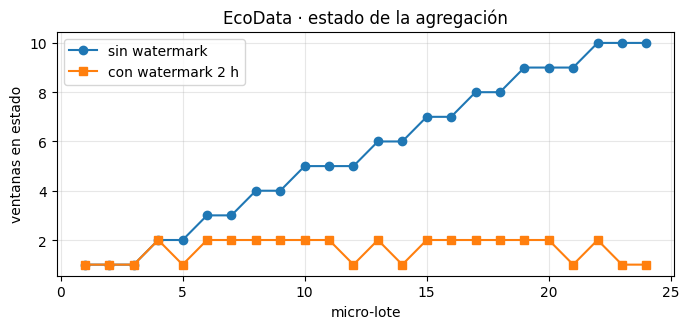

In [ ]:
# Evidencia gráfica: estado en memoria, sin y con watermark
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(e_sin["batchId"], e_sin["ventanas_en_estado"], "o-", label="sin watermark")
ax.plot(e_con["batchId"], e_con["ventanas_en_estado"], "s-", label="con watermark 2 h")
ax.set_xlabel("micro-lote"); ax.set_ylabel("ventanas en estado"); ax.set_title("EcoData · estado de la agregación"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

**Captura:** las dos tablas de estado (la columna `ventanas_en_estado` sube sin tope en la primera y se estabiliza en la segunda) y el gráfico. En tu informe, explica cada modo de salida y por qué `complete` solo es posible sin watermark.

In [ ]:
detener_todo(); print("consultas detenidas")

consultas detenidas


## S8 · 5. Ventana deslizante 6 h con paso de 2 h (3.9)
Con el paso menor que el ancho, **cada lectura cae en tres ventanas** (`6 h / 2 h = 3`). Sirve para suavizar la métrica, a costa de guardar más estado.

In [ ]:
detener_todo()
q_des, sal_des = recolector(agregar(eventos, wm="2 hours", ancho="6 hours", paso="2 hours"), "update", "e2_deslizante")
time.sleep(8)
hilo = publicar_paced(TOPIC, [ev(i) for i in range(24)], pausa_s=1.5)
hilo.join(timeout=120); time.sleep(12)
q_des.stop()
df_des = pd.DataFrame(sal_des).drop(columns="batchId").drop_duplicates(["ventana_inicio", "sensorId"], keep="last").sort_values("ventana_inicio")
print("ventanas distintas que produjeron las 24 horas publicadas:", len(df_des), "(con ventana fija serían ~4–5)")
df_des

ventanas distintas que produjeron las 24 horas publicadas: 14 (con ventana fija serían ~4–5)


,ventana_inicio,ventana_fin,sensorId,n,pm25_prom,pm25_max
6,2023-12-27 20:00:00,2023-12-28 02:00:00,openmeteo-cams-juliaca,2,6.20,6.2
8,2023-12-27 22:00:00,2023-12-28 04:00:00,openmeteo-cams-juliaca,4,6.00,6.2
9,2023-12-28 00:00:00,2023-12-28 06:00:00,openmeteo-cams-juliaca,6,6.23,6.7
11,2023-12-28 02:00:00,2023-12-28 08:00:00,openmeteo-cams-juliaca,6,6.23,6.7
18,2023-12-28 04:00:00,2023-12-28 10:00:00,openmeteo-cams-juliaca,6,6.20,6.7
21,2023-12-28 06:00:00,2023-12-28 12:00:00,openmeteo-cams-juliaca,6,5.82,6.3
20,2023-12-28 08:00:00,2023-12-28 14:00:00,openmeteo-cams-juliaca,6,4.42,5.8
23,2023-12-28 10:00:00,2023-12-28 16:00:00,openmeteo-cams-juliaca,6,3.02,5.6
29,2023-12-28 12:00:00,2023-12-28 18:00:00,openmeteo-cams-juliaca,6,1.57,2.1
32,2023-12-28 14:00:00,2023-12-28 20:00:00,openmeteo-cams-juliaca,6,1.22,1.6


**Captura:** la tabla. Elige una hora concreta y señala las tres ventanas solapadas que la contienen.

## S8 · 6. Dato tardío y watermark (3.11 · punto 3 de la actividad)
Se publican 25 horas en orden y luego, en el medio del flujo:
- `ec-tolerado`: una lectura **1 h** más vieja que la última (dentro del margen de 2 h → **debe aparecer**).
- `ec-tardio`: una lectura **24 h** más vieja (fuera del margen → **debe desaparecer sin ningún error**).

Una segunda consulta, **sin agregación**, lee el mismo flujo en crudo: prueba que `ec-tardio` *sí llegó* a Spark y que, aun así, la agregación no lo cuenta. (Advertencia de arranque en frío: si el tardío fuera el primer mensaje que ve la consulta, el watermark aún no tendría referencia y se aceptaría; por eso primero van 25 horas normales.)

In [ ]:
detener_todo()
q_raw, sal_raw = recolector(eventos.select("sensorId", "ts", "pm25", "origen"), "append", "e3_crudo")
q_agg, sal_agg = recolector(agregar(eventos, wm="2 hours"), "update", "e3_agregado")
time.sleep(8)

normales = [ev(i) for i in range(31)]
ultimo_ts = normales[24]["timestamp"]
tolerado = ev(20, "prueba-tolerado"); tolerado.update(sensorId="ec-tolerado", timestamp=ultimo_ts - 1*3600*1000)
tardio   = ev(5,  "prueba-tardio");   tardio.update(sensorId="ec-tardio",   timestamp=ultimo_ts - 24*3600*1000)
flujo = normales[:25] + [tolerado, tardio] + normales[25:]
hilo = publicar_paced(TOPIC, flujo, pausa_s=1.5)
print("publicando", len(flujo), "eventos (~50 s). Tardío =", datetime.fromtimestamp(tardio["timestamp"]/1000, timezone.utc), "UTC")

publicando 33 eventos (~50 s). Tardío = 2023-12-28 00:00:00+00:00 UTC


In [ ]:
hilo.join(timeout=120); time.sleep(14)
crudo_df = pd.DataFrame(sal_raw)
agg_df = pd.DataFrame(sal_agg)
for s in ("ec-tolerado", "ec-tardio"):
    print(f"{s:12s} · llegó a Spark (lectura cruda): {(crudo_df.sensorId == s).sum()} vez/veces · "
          f"aparece en la agregación con watermark: {'SÍ' if (agg_df.sensorId == s).any() else 'NO'}")
print("\nEl tardío en crudo:")
display(crudo_df[crudo_df.sensorId == "ec-tardio"][["batchId", "sensorId", "ts", "pm25", "origen"]])
print("Filas de ventana con sensorId distinto del principal (el tolerado debe estar, el tardío no):")
display(agg_df[agg_df.sensorId.str.startswith("ec-t")].drop_duplicates(["ventana_inicio", "sensorId"], keep="last"))

ec-tolerado  · llegó a Spark (lectura cruda): 1 vez/veces · aparece en la agregación con watermark: SÍ
ec-tardio    · llegó a Spark (lectura cruda): 1 vez/veces · aparece en la agregación con watermark: NO

El tardío en crudo:


,batchId,sensorId,ts,pm25,origen
26,11,ec-tardio,2023-12-28,6.7,prueba-tardio


Filas de ventana con sensorId distinto del principal (el tolerado debe estar, el tardío no):


,ventana_inicio,ventana_fin,sensorId,n,pm25_prom,pm25_max,batchId
11,2023-12-28 18:00:00,2023-12-29,ec-tolerado,1,0.9,0.9,10


In [ ]:
detener_todo(); print("consultas detenidas")

consultas detenidas


**Captura:** el `print` de dos líneas y las dos tablas. El mensaje clave: `ec-tardio` aparece en crudo y **no** en la agregación; `ec-tolerado` aparece en ambas.

## S8 · 7. Deduplicación acotada por watermark (3.12 · punto 4)
Se publica **dos veces** la misma lectura (`ec-duplicado`). La consulta de crudo la ve dos veces; la deduplicada, una.

> Detalle técnico: `dropDuplicates` solo puede limpiar su estado si la **columna de tiempo del watermark (`ts`) forma parte de las columnas de deduplicación**; por eso aquí se usa `["sensorId", "ts"]` y no el `timestamp` numérico. Con el numérico, Spark guardaría cada identificador para siempre.

In [ ]:
detener_todo()
q_raw2, sal_raw2 = recolector(eventos.select("sensorId", "ts", "pm25", "origen"), "append", "e4_crudo")
dedup = eventos.withWatermark("ts", "2 hours").dropDuplicates(["sensorId", "ts"]).select("sensorId", "ts", "pm25", "origen")
q_ded, sal_ded = recolector(dedup, "append", "e4_dedup", trigger="3 seconds")
time.sleep(8)

base = [ev(i) for i in range(10)]
dup = ev(9, "prueba-duplicado"); dup["sensorId"] = "ec-duplicado"
hilo = publicar_paced(TOPIC, base + [dup, dup] + [ev(i) for i in range(10, 16)], pausa_s=1.0)
hilo.join(timeout=60); time.sleep(12)

r = pd.DataFrame(sal_raw2); d = pd.DataFrame(sal_ded)
print("ec-duplicado publicado 2 veces → lectura cruda:", (r.sensorId == "ec-duplicado").sum(),
      "· tras dropDuplicates con watermark:", (d.sensorId == "ec-duplicado").sum())
display(d[d.sensorId == "ec-duplicado"])
print("total crudo:", len(r), "· total deduplicado:", len(d))

ec-duplicado publicado 2 veces → lectura cruda: 2 · tras dropDuplicates con watermark: 1


,sensorId,ts,pm25,origen,batchId
9,ec-duplicado,2023-12-28 09:00:00,5.6,prueba-duplicado,4


total crudo: 18 · total deduplicado: 17


In [ ]:
detener_todo(); print("consultas detenidas")

consultas detenidas


**Captura:** el `print` (2 → 1) y la tabla. Relaciónalo con la semántica *at-least-once* de Kafka (S6): el duplicado es lo que un reintento podría producir.

## S8 · 8. Intervalo de disparo: 1 s frente a 6 s (3.13 · punto 5)
Mismo flujo, mismo tiempo de reloj (15 s cada uno). Además del `batchId` que pide la guía se mide cuántas filas procesó cada micro-lote y la **latencia real** (llegada a Kafka → procesamiento), que es lo que el intervalo compromete.

In [ ]:
detener_todo()
def medir(intervalo, segundos):
    nombre = "trg_" + intervalo.replace(" ", "_")
    df = eventos.withColumn("lat_ms", F.unix_millis(F.current_timestamp()) - F.unix_millis(F.col("kafkaTimestamp")))
    q = (df.writeStream.outputMode("append").format("memory").queryName(nombre)
         .trigger(processingTime=intervalo).start())
    q.awaitTermination(segundos); q.stop()
    prog = [p for p in q.recentProgress]
    lat = spark.sql(f"SELECT avg(lat_ms) a, max(lat_ms) m FROM {nombre}").first()
    return {"intervalo": intervalo, "ultimo_batchId": max((p["batchId"] for p in prog), default=None),
            "microlotes_con_datos": sum(1 for p in prog if p["numInputRows"] > 0),
            "filas_procesadas": sum(p["numInputRows"] for p in prog),
            "latencia_prom_ms": round(lat["a"] or 0), "latencia_max_ms": lat["m"]}

hilo = publicar_paced(TOPIC, [ev(i) for i in range(120)], pausa_s=0.4)   # flujo continuo ~48 s
time.sleep(3)
res = [medir("1 second", 15), medir("6 seconds", 15)]
hilo.join(timeout=60)
pd.DataFrame(res)

26/11/06 02:20:30 ERROR WriteToDataSourceV2Exec: Data source write support MicroBatchWrite[epoch: 15, writer: org.apache.spark.sql.execution.streaming.sources.MemoryStreamingWrite@1540ce84] is aborting.
26/11/06 02:20:30 ERROR WriteToDataSourceV2Exec: Data source write support MicroBatchWrite[epoch: 15, writer: org.apache.spark.sql.execution.streaming.sources.MemoryStreamingWrite@1540ce84] aborted.
26/11/06 02:20:30 ERROR Utils: Aborting task
org.apache.spark.TaskKilledException: Stage cancelled: [SPARK_JOB_CANCELLED] Job 123 cancelled Query trg_1_second [id = 0e957bed-d3cd-4586-bd7e-c696f040362a, runId = 3dae19f2-b160-4d8d-8dfe-9db331f6205a] was stopped SQLSTATE: XXKDA
	at org.apache.spark.TaskContextImpl.killTaskIfInterrupted(TaskContextImpl.scala:342)
	at org.apache.spark.InterruptibleIterator.hasNext(InterruptibleIterator.scala:36)
	at scala.collection.Iterator$$anon$10.hasNext(Iterator.scala:610)
	at scala.collection.Iterator$$anon$9.hasNext(Iterator.scala:593)
	at scala.collectio

,intervalo,ultimo_batchId,microlotes_con_datos,filas_procesadas,latencia_prom_ms,latencia_max_ms
0,1 second,14,14,34,522,1010
1,6 seconds,2,2,29,2771,5667


**Captura:** la tabla. Lectura esperada: con 1 s hay más micro-lotes y menos filas por lote, y la latencia es menor; con 6 s ocurre lo contrario. El log puede mostrar `TaskKilledException` al detener: es ruido de `stop()`, no una falla.

**Para EcoData:** los datos llegan por hora, así que un disparo de 1 s es puro gasto; el job de producción dispara cada 5 min. Para una alerta de episodio (que debe salir en minutos) ese intervalo ya es más que suficiente.

## S8 · 9. Checkpoint: qué guarda y qué pasa al reiniciar (3.10)
Se inspecciona el checkpoint de la consulta con watermark de la sección 4 (la que tiene estado).

In [ ]:
base_chk = "./artifacts/s08/chk_e1_con_watermark"
print("Contenido del checkpoint:", sorted(os.listdir(base_chk)))
for sub in ("offsets", "commits", "state"):
    ruta = os.path.join(base_chk, sub)
    if os.path.isdir(ruta):
        n = sum(len(f) for _, _, f in os.walk(ruta))
        print(f"  {sub}/ → {n} archivos")
ult = sorted(os.listdir(base_chk + "/offsets"), key=lambda x: int(x) if x.isdigit() else -1)[-1]
print(f"\nÚltimo archivo de offsets (lote {ult}):")
print(open(f"{base_chk}/offsets/{ult}").read())

Contenido del checkpoint: ['.metadata.crc', 'commits', 'metadata', 'offsets', 'sources', 'state']
  offsets/ → 52 archivos
  commits/ → 52 archivos
  state/ → 170 archivos

Último archivo de offsets (lote 25):
v1
{"batchWatermarkMs":1703926800000,"batchTimestampMs":1793930796005,"conf":{"spark.sql.streaming.stateStore.providerClass":"org.apache.spark.sql.execution.streaming.state.HDFSBackedStateStoreProvider","spark.sql.streaming.stateStore.rocksdb.mergeOperatorVersion":"2","spark.sql.streaming.stateStore.rocksdb.formatVersion":"5","spark.sql.streaming.queryEvolution.enableSourceEvolution":"false","spark.sql.streaming.stateStore.encodingFormat":"unsaferow","spark.sql.streaming.statefulOperator.useStrictDistribution":"true","spark.sql.streaming.flatMapGroupsWithState.stateFormatVersion":"2","spark.sql.streaming.multipleWatermarkPolicy":"min","spark.sql.streaming.stateStore.rowChecksum.enabled":"false","spark.sql.streaming.aggregation.stateFormatVersion":"2","spark.sql.function.protobufE

- `offsets/`: hasta qué offset de cada partición se leyó, por micro-lote.
- `commits/`: qué micro-lotes terminaron de escribirse.
- `state/`: el contenido de las ventanas abiertas.

El reinicio con el mismo checkpoint se **demuestra en la sección 11** (segunda corrida a Parquet): la consulta retoma desde el último offset confirmado, sin releer el topic y sin duplicar.

## S8 · 10. Errores provocados a propósito (para el apartado «Error o hallazgo»)

In [ ]:
detener_todo()
def intentar(titulo, fn):
    try:
        fn(); print(f"· {titulo}: NO falló en esta versión de Spark")
    except Exception as ex:
        print(f"· {titulo}:\n    {type(ex).__name__}: {str(ex).splitlines()[0][:230]}")

def sin_checkpoint():
    q = agregar(eventos, wm="2 hours").writeStream.outputMode("update").foreachBatch(lambda b, i: None).start()
    q.stop()
def update_a_parquet():
    q = (agregar(eventos, wm="2 hours").writeStream.outputMode("update").format("parquet")
         .option("path", "./artifacts/s08/no_usar").option("checkpointLocation", chk("e5_error")).start())
    q.stop()
intentar("Consulta con estado SIN checkpointLocation", sin_checkpoint)
intentar("Agregación en modo update escrita directo a Parquet", update_a_parquet)
detener_todo()

· Consulta con estado SIN checkpointLocation: NO falló en esta versión de Spark
· Agregación en modo update escrita directo a Parquet:
    AnalysisException: [STREAMING_OUTPUT_MODE.UNSUPPORTED_DATASOURCE] Invalid streaming output mode: update. This output mode is not supported in Data Source parquet. SQLSTATE: 42KDE


**Captura:** los dos mensajes. Cualquiera de ellos puede ser tu «error diagnosticado» del informe (preguntas de defensa 2 y 4).

## S8 · 11. Persistencia en Parquet con checkpoint: dos corridas que acumulan (3.6 · punto 6)
Primera corrida: 20 horas. Se detiene la consulta. Segunda corrida: **mismo checkpoint, misma carpeta**, 15 horas nuevas. Debe acumular (35 filas), no sobreescribir, y retomar donde quedó.

In [ ]:
RUTA = "./artifacts/s08/parquet_aire"; CHK_P = chk("e6_parquet"); shutil.rmtree(RUTA, ignore_errors=True)
def corrida(horas, etiqueta):
    q = (eventos.select("sensorId", "pm25", "pm10", "ts", "origen").writeStream.outputMode("append").format("parquet")
         .option("path", RUTA).option("checkpointLocation", CHK_P).trigger(processingTime="4 seconds").start())
    time.sleep(6)
    publicar_paced(TOPIC, [ev(i) for i in horas], pausa_s=1.0).join(timeout=60)
    time.sleep(12); q.stop()
    lotes = [p["batchId"] for p in q.recentProgress if p["numInputRows"] > 0]
    n = spark.read.parquet(RUTA).count()
    print(f"{etiqueta}: micro-lotes {lotes} · filas totales en Parquet: {n}")
    return n, lotes

n1, l1 = corrida(range(0, 20), "Corrida 1")
n2, l2 = corrida(range(20, 35), "Corrida 2")
print("\n¿Acumuló en vez de sobreescribir?", n2 > n1, f"({n1} → {n2}; esperado +15 = {n1 + 15})")
print("¿La corrida 2 retomó desde el checkpoint (batchId mayor que el último de la corrida 1)?", bool(l1 and l2 and min(l2) > max(l1)))

Corrida 1: micro-lotes [1, 2, 3, 4, 5, 6] · filas totales en Parquet: 20


Corrida 2: micro-lotes [7, 8, 9, 10, 11] · filas totales en Parquet: 35

¿Acumuló en vez de sobreescribir? True (20 → 35; esperado +15 = 35)
¿La corrida 2 retomó desde el checkpoint (batchId mayor que el último de la corrida 1)? True


In [ ]:
spark.read.parquet(RUTA).groupBy("sensorId").agg(F.count("*").alias("filas"), F.min("ts").alias("desde"), F.max("ts").alias("hasta")).show(truncate=False)
print("Archivos Parquet en disco:", len(glob.glob(RUTA + "/*.parquet")))
print("Offsets confirmados en el checkpoint:", sorted(os.listdir(CHK_P + "/offsets"))[-3:])

+----------------------+-----+-------------------+-------------------+
|sensorId              |filas|desde              |hasta              |
+----------------------+-----+-------------------+-------------------+
|openmeteo-cams-juliaca|35   |2023-12-28 00:00:00|2023-12-29 10:00:00|
+----------------------+-----+-------------------+-------------------+

Archivos Parquet en disco: 12
Offsets confirmados en el checkpoint: ['7', '8', '9']


**Captura:** la salida de las dos corridas con el veredicto, y la tabla resumen.

## S8 · 12. Cierre
Detén lo que quede activo y guarda estas capturas (cada una **con el reloj del sistema y tu usuario/perfil visibles**):

1. Sección 2 — `printSchema` y la excepción al materializar un stream.
2. Sección 4 — tablas de estado sin/con watermark + gráfico.
3. Sección 5 — ventana deslizante.
4. Sección 6 — tardío descartado y tolerado aceptado.
5. Sección 7 — duplicado (2 → 1).
6. Sección 8 — comparación de intervalos de disparo.
7. Sección 9 — contenido del checkpoint.
8. Sección 10 — errores provocados.
9. Sección 11 — dos corridas que acumulan.
10. Kafka UI (http://localhost:48085) con el topic `ecodata-s08-aire`.

In [ ]:
detener_todo()
spark.stop()
print("listo. Sube este cuaderno y la carpeta artifacts/s08 (sin los checkpoints) a tu repositorio el mismo día.")

# Parte 4 · Sesión 9: Observabilidad con Prometheus y Grafana, y costos

**Lanzeloth Vargas Marichi** · Proyecto Sello EcoData · Big Data, UPeU

La guía instrumenta un pipeline de streaming con métricas de **infraestructura** (Kafka → kafka-exporter → Prometheus → Grafana) y de **aplicación** (campos calculados en Spark). EcoData ya tiene Prometheus, Grafana, Pushgateway y 8 alertas en producción (S12); este cuaderno genera la evidencia que pide S9 sobre esa misma infraestructura.

| Guía S9 | EcoData |
|---|---|
| topic `atmos-eventos` | **`ecodata-s09-lecturas`** (lecturas reales de PM2.5/PM10 de Juliaca, Open-Meteo) |
| grupo `uso-atmos-group` | **`ec-alerta-ms-group`** y **`validador-ecodata-group`** (creados en S6 y S7) |
| `isValid`, `processedAt`, `latencyMs` | iguales, calculados en Spark; `latencyMs` = proceso − **llegada a Kafka** |
| alertas propuestas (Tabla 8) | las 8 reglas **ya implementadas** en `alerts.yml`, más umbrales nuevos calculados con datos medidos |
| costos (Tabla 9) | plantilla con tus valores medidos y el costo de `operacion.md` |

> **Antes de empezar:** Kafka, Prometheus (49090), Grafana (43000) y Pushgateway deben estar levantados; haz S6 antes (crea los grupos de consumo que se ven en el lag). Para que Spark no se quede sin memoria, **cierra otros cuadernos** de Spark que tengas abiertos (Kernel → Shut down).
>
> **Transparencia:** los eventos de este cuaderno son horas reales de la API publicadas **a ritmo controlado** (1 cada 2 s) para poder observar latencia y rendimiento; no son un sensor en vivo.

## S9 · 0. Preparación

In [ ]:
import sys, json, time, threading, urllib.request, urllib.parse, os
from datetime import datetime, timezone
import pandas as pd
sys.path.insert(0, "/tmp/s12/scripts")
import aire_comun as aire
import openmeteo_a_kafka as pub_aire
from kafka import KafkaProducer, KafkaConsumer, TopicPartition
from kafka.admin import KafkaAdminClient, NewTopic
from kafka.errors import TopicAlreadyExistsError

BOOTSTRAP = "kafka:9092"
PUSHGATEWAY = "http://pushgateway:9091"
PROMETHEUS_CANDIDATOS = ["http://prometheus:9090", "http://lambda26-prometheus:9090"]
PKG = "org.apache.spark:spark-sql-kafka-0-10_2.13:4.2.0"

def crear_topic(nombre, particiones=3):
    adm = KafkaAdminClient(bootstrap_servers=BOOTSTRAP)
    try: adm.create_topics([NewTopic(nombre, num_partitions=particiones, replication_factor=1)]); print("topic creado:", nombre)
    except TopicAlreadyExistsError: print("el topic ya existía:", nombre)
    adm.close()

def prom(q):
    for base in PROMETHEUS_CANDIDATOS:
        try:
            u = f"{base}/api/v1/query?" + urllib.parse.urlencode({"query": q})
            return json.load(urllib.request.urlopen(u, timeout=4))["data"]["result"]
        except Exception:
            continue
    return None

def publicar_paced(topic, eventos, pausa_s=2.0):
    """Publica un evento cada pausa_s segundos en segundo plano (la celda no se bloquea)."""
    def run():
        p = KafkaProducer(bootstrap_servers=BOOTSTRAP, acks="all", key_serializer=str.encode,
                          value_serializer=lambda v: json.dumps(v).encode())
        for e in eventos:
            p.send(topic, key=e["sensorId"], value=e); p.flush(); time.sleep(pausa_s)
        p.close()
    th = threading.Thread(target=run, daemon=True); th.start(); return th

def desde_archivo(path="/tmp/s12/aq_juliaca_2023.json"):
    d = json.load(open(path)); h = d.get("hourly", d); out = []
    for t, a, b in zip(h["time"], h["pm2_5"], h["pm10"]):
        if a is None: continue
        ts = int(datetime.fromisoformat(t).replace(tzinfo=timezone.utc).timestamp() * 1000)
        out.append((ts, float(a), float(b) if b is not None else float(a)))
    return out

TOPIC = "ecodata-s09-lecturas"
crear_topic(TOPIC)

topic creado: ecodata-s09-lecturas


## S9 · 1. Prometheus: targets y consultas PromQL (3.1–3.2)
Verifica a mano en http://localhost:49090 → **Status → Targets** (`kafka-exporter`, `pushgateway` y `prometheus` en **UP**) y captura la pantalla. Luego corre las consultas desde aquí:

In [ ]:
consultas = {
  "kafka_brokers": "kafka_brokers",
  "exporter arriba": 'up{job="kafka-exporter"}',
  "pushgateway arriba": 'up{job="pushgateway"}',
  "lag ec-alerta-ms-group": 'sum(kafka_consumergroup_lag{consumergroup="ec-alerta-ms-group"})',
  "lag validador-ecodata-group": 'sum(kafka_consumergroup_lag{consumergroup="validador-ecodata-group"})',
  "mensajes en atmos-aire": 'sum(kafka_topic_partition_current_offset{topic="atmos-aire"})',
}
for nombre, q in consultas.items():
    r = prom(q)
    print(f"{nombre:30s}", "SIN RESPUESTA de Prometheus" if r is None else (r[0]["value"][1] if r else "sin datos (¿el grupo ya existe? corre S6/S7)"))

kafka_brokers                  1
exporter arriba                1
pushgateway arriba             1
lag ec-alerta-ms-group         0
lag validador-ecodata-group    0
mensajes en atmos-aire         12983


**Tablero de Grafana (3.3):** importa `s09_dashboard_ecodata.json` (Dashboards → New → Import → Upload JSON file, datasource Prometheus). Trae los cuatro paneles de la guía (Kafka Brokers, Exporter Up, Broker Info, Consumer Lag) más lag por grupo y estado de los jobs de EcoData.

## S9 · 2. Spark: lectura streaming con campos de observabilidad (3.4–3.5)
`isValid` reutiliza el contrato mínimo; `processedAt` es el instante en que Spark procesa; `latencyMs = processedAt − kafkaTimestamp` mide cuánto tardó el evento desde que llegó al broker hasta Spark (el `timestamp` del evento es la **hora del dato** y puede ser de horas atrás, por eso no sirve para medir latencia del pipeline).

In [ ]:
from pyspark.sql import SparkSession, functions as F
from pyspark.sql.types import StructType, StringType, DoubleType, LongType
esquema_evento = (StructType().add("tipoEvento", StringType()).add("sensorId", StringType())
                  .add("pm25", DoubleType()).add("pm10", DoubleType())
                  .add("origen", StringType()).add("timestamp", LongType()))
spark = (SparkSession.builder.appName("ecodata-s09").master("local[2]")
         .config("spark.jars.packages", PKG)
         .config("spark.sql.shuffle.partitions", "3")
         .config("spark.sql.session.timeZone", "UTC")
         .config("spark.ui.port", "4050")          # distinto del 4040 que usan los jobs de S12
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
print("Spark", spark.version)

:: loading settings :: url = jar:file:/usr/local/lib/python3.10/site-packages/pyspark/jars/ivy-2.5.3.jar!/org/apache/ivy/core/settings/ivysettings.xml
Ivy Default Cache set to: /root/.ivy2.5.2/cache
The jars for the packages stored in: /root/.ivy2.5.2/jars
org.apache.spark#spark-sql-kafka-0-10_2.13 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-7619816b-f24f-41d1-ad67-e8415a1f8edc;1.0
	confs: [default]
	found org.apache.spark#spark-sql-kafka-0-10_2.13;4.2.0 in spark-list
	found org.apache.spark#spark-token-provider-kafka-0-10_2.13;4.2.0 in central
	found org.apache.kafka#kafka-clients;3.9.2 in central
	found at.yawk.lz4#lz4-java;1.11.0 in central
	found org.xerial.snappy#snappy-java;1.1.10.8 in central
	found org.slf4j#slf4j-api;2.0.17 in central
	found org.apache.hadoop#hadoop-client-runtime;3.5.0 in central
	found org.apache.hadoop#hadoop-client-api;3.5.0 in central
	found com.google.code.findbugs#jsr305;3.0.0 in central
	found org.scala-lang.

Spark 4.2.0


In [ ]:
crudo = (spark.readStream.format("kafka").option("kafka.bootstrap.servers", BOOTSTRAP)
         .option("subscribe", "ecodata-s09-lecturas").option("startingOffsets", "latest").option("failOnDataLoss", "false").load())
eventos = (crudo.select("topic", "partition", "offset", F.col("timestamp").alias("kafkaTimestamp"),
                        F.from_json(F.col("value").cast("string"), esquema_evento).alias("e"))
           .select("topic", "partition", "offset", "kafkaTimestamp", "e.*"))
observables = (eventos
    .withColumn("isValid", F.col("tipoEvento").isNotNull() & F.col("sensorId").isNotNull() & F.col("pm25").isNotNull()
                           & F.col("pm10").isNotNull() & F.col("timestamp").isNotNull() & (F.col("pm25") >= 0))
    .withColumn("processedAt", F.unix_millis(F.current_timestamp()))
    .withColumn("latencyMs", F.col("processedAt") - F.unix_millis(F.col("kafkaTimestamp"))))
observables.printSchema()

root
 |-- topic: string (nullable = true)
 |-- partition: integer (nullable = true)
 |-- offset: long (nullable = true)
 |-- kafkaTimestamp: timestamp (nullable = true)
 |-- tipoEvento: string (nullable = true)
 |-- sensorId: string (nullable = true)
 |-- pm25: double (nullable = true)
 |-- pm10: double (nullable = true)
 |-- origen: string (nullable = true)
 |-- timestamp: long (nullable = true)
 |-- isValid: boolean (nullable = true)
 |-- processedAt: long (nullable = false)
 |-- latencyMs: long (nullable = true)



## S9 · 3. Salida dual: Parquet + bitácora por micro-lote (3.6 y 3.8)
Cada micro-lote se guarda en Parquet y deja una línea en una bitácora con el formato de logs de la guía. (La consola de Spark no se ve en la celda de Jupyter, por eso la bitácora la reemplaza.)

In [ ]:
RUTA = "./artifacts/s09_eventos_observabilidad"; CHK = "./artifacts/chk_s09"
bitacora = []
def por_microlote(df, bid):
    n = df.count()
    if n == 0:
        bitacora.append(dict(service="spark-streaming", component="observabilidad", batchId=bid, numInputRows=0, status="idle")); return
    df.write.mode("append").parquet(RUTA)
    r = df.agg(F.avg("latencyMs").alias("lat"), F.sum((~F.col("isValid")).cast("int")).alias("inval")).first()
    bitacora.append(dict(service="spark-streaming", component="observabilidad", topic="ecodata-s09-lecturas", batchId=bid,
                         numInputRows=n, avgLatencyMs=round(r["lat"], 1), invalidos=int(r["inval"]), status="processed"))

consulta = (observables.writeStream.foreachBatch(por_microlote)
            .option("checkpointLocation", CHK).trigger(processingTime="5 seconds").start())
print("consulta activa:", consulta.isActive)

consulta activa: True


Con la consulta activa, **publica el flujo** (45 lecturas reales, una cada 2 s ≈ 90 s). No detengas la consulta todavía.

In [ ]:
serie = pub_aire.desde_api()                                   # [(ts_ms, pm25, pm10)]
paced = [aire.evento(t, a, b, "openmeteo-cams") for t, a, b in (serie * 3)[-45:]]
hilo = publicar_paced(TOPIC, paced, pausa_s=2.0)
print(len(paced), "eventos en camino hacia", TOPIC)

45 eventos en camino hacia ecodata-s09-lecturas


## S9 · 4. lastProgress: throughput y lag del lado de Spark (3.7)
Espera ~40 s desde la celda anterior y corre esta celda **dos o tres veces**.

In [ ]:
p = consulta.lastProgress
if p is None:
    print("Todavía no hay micro-lote procesado. Espera unos segundos y repite.")
else:
    m = p["sources"][0].get("metrics", {})
    print(json.dumps({"service": "spark-streaming", "component": "observabilidad", "topic": "ecodata-s09-lecturas",
        "batchId": p["batchId"], "numInputRows": p["numInputRows"], "inputRowsPerSecond": p["inputRowsPerSecond"],
        "processedRowsPerSecond": p["processedRowsPerSecond"], "avgOffsetsBehindLatest": m.get("avgOffsetsBehindLatest"),
        "maxOffsetsBehindLatest": m.get("maxOffsetsBehindLatest"),
        "status": "idle" if p["numInputRows"] == 0 else "processed"}, indent=2))
print("\nÚltimas líneas de la bitácora:")
for b in bitacora[-5:]: print(json.dumps(b))

{
  "service": "spark-streaming",
  "component": "observabilidad",
  "topic": "ecodata-s09-lecturas",
  "batchId": 7,
  "numInputRows": 15,
  "inputRowsPerSecond": 3.0,
  "processedRowsPerSecond": 6.5,
  "avgOffsetsBehindLatest": "0.0",
  "maxOffsetsBehindLatest": "0",
  "status": "processed"
}

Últimas líneas de la bitácora:
{"service": "spark-streaming", "component": "observabilidad", "topic": "ecodata-s09-lecturas", "batchId": 3, "numInputRows": 3, "avgLatencyMs": 2701.3, "invalidos": 0, "status": "processed"}
{"service": "spark-streaming", "component": "observabilidad", "topic": "ecodata-s09-lecturas", "batchId": 4, "numInputRows": 2, "avgLatencyMs": 2688.0, "invalidos": 0, "status": "processed"}
{"service": "spark-streaming", "component": "observabilidad", "topic": "ecodata-s09-lecturas", "batchId": 5, "numInputRows": 3, "avgLatencyMs": 2673.3, "invalidos": 0, "status": "processed"}
{"service": "spark-streaming", "component": "observabilidad", "topic": "ecodata-s09-lecturas", "bat

Evidencia alternativa: **Spark UI** en http://localhost:4050 → *Structured Streaming* (el puerto 4050 evita chocar con los jobs de S12, que usan 4040; si no abre desde tu navegador, usa el bloque de arriba).

In [ ]:
hilo.join(timeout=120)          # espera a que termine la publicación
time.sleep(12)                  # y a que Spark procese el último micro-lote
consulta.stop()
guardado = spark.read.parquet(RUTA)
print("filas guardadas:", guardado.count())
guardado.select("partition", "offset", "sensorId", "pm25", "isValid", "latencyMs").orderBy(F.desc("offset")).show(10, truncate=False)

filas guardadas: 90
+---------+------+----------------------+----+-------+---------+
|partition|offset|sensorId              |pm25|isValid|latencyMs|
+---------+------+----------------------+----+-------+---------+
|1        |89    |openmeteo-cams-juliaca|2.1 |true   |4729     |
|1        |88    |openmeteo-cams-juliaca|2.0 |true   |1735     |
|1        |87    |openmeteo-cams-juliaca|1.7 |true   |3739     |
|1        |86    |openmeteo-cams-juliaca|1.4 |true   |744      |
|1        |85    |openmeteo-cams-juliaca|1.1 |true   |2750     |
|1        |84    |openmeteo-cams-juliaca|1.0 |true   |4755     |
|1        |83    |openmeteo-cams-juliaca|0.9 |true   |1761     |
|1        |82    |openmeteo-cams-juliaca|0.9 |true   |3765     |
|1        |81    |openmeteo-cams-juliaca|0.9 |true   |769      |
|1        |80    |openmeteo-cams-juliaca|0.8 |true   |2774     |
+---------+------+----------------------+----+-------+---------+
only showing top 10 rows


## S9 · 5. Latencia agregada por ventana de tiempo (3.9)

In [ ]:
lat = (spark.read.parquet(RUTA).groupBy(F.window("kafkaTimestamp", "1 minute"))
       .agg(F.count("*").alias("numEventos"), F.avg("latencyMs").alias("avgLatencyMs"),
            F.min("latencyMs").alias("minLatencyMs"), F.max("latencyMs").alias("maxLatencyMs"))
       .select(F.col("window.start").alias("inicioVentana"), "numEventos", "avgLatencyMs", "minLatencyMs", "maxLatencyMs")
       .orderBy("inicioVentana"))
lat.show(truncate=False)
EXPLICACION = ("El productor envía cada 2 s y Spark dispara cada 5 s: no son múltiplos (mcm = 10 s), así que la espera de "
               "cada evento hasta el siguiente disparo cicla entre ~0 y ~5 s. Esa es la variación de min/max: aritmética, no una falla.")
print(EXPLICACION)

+-------------------+----------+------------------+------------+------------+
|inicioVentana      |numEventos|avgLatencyMs      |minLatencyMs|maxLatencyMs|
+-------------------+----------+------------------+------------+------------+
|2026-11-06 02:50:00|20        |2533.55           |646         |4707        |
|2026-11-06 02:51:00|59        |2749.2542372881358|520         |4926        |
|2026-11-06 02:52:00|11        |2936.3636363636365|744         |4779        |
+-------------------+----------+------------------+------------+------------+

El productor envía cada 2 s y Spark dispara cada 5 s: no son múltiplos (mcm = 10 s), así que la espera de cada evento hasta el siguiente disparo cicla entre ~0 y ~5 s. Esa es la variación de min/max: aritmética, no una falla.


## S9 · 6. Alertas con umbrales justificados por datos medidos (3.10)

In [ ]:
pl = spark.read.parquet(RUTA).select("latencyMs").toPandas()["latencyMs"]
p50, p95, mx = pl.quantile(.50), pl.quantile(.95), pl.max()
u_sens, u_crit = int(round(2 * p95, -2)), int(round(10 * p95, -2))
print(f"latencia medida: p50={p50:.0f} ms · p95={p95:.0f} ms · máx={mx:.0f} ms")
alertas = pd.DataFrame([
  ["Kafka no visible", "kafka_brokers < 1", "Prometheus", "ya implementada como PushgatewayCaido (caída del gateway); añadir esta para Kafka"],
  ["Exporter caído", 'up{job="kafka-exporter"} == 0', "Prometheus", "propuesta"],
  ["Lag alto sostenido", 'sum(kafka_consumergroup_lag{consumergroup="ec-alerta-ms-group"}) > 100 (for 2m)', "Prometheus", "propuesta; el lag normal medido en S6 vuelve a 0"],
  ["Latencia sensible", f"avgLatencyMs por minuto > {u_sens} ms (2×p95 medido)", "Spark / Parquet", "propuesta con tu p95"],
  ["Latencia crítica", f"avgLatencyMs por minuto > {u_crit} ms (10×p95 medido)", "Spark / Parquet", "propuesta con tu p95"],
  ["Sin eventos nuevos", "time() - push_time_seconds{job=lambda26_aire} > 600  or absent(...)", "Prometheus", "IMPLEMENTADA (alerts.yml): AireSinEventosNuevos"],
  ["Modelo no supera persistencia", "lambda26_aire_mejora_pct < 0 (10 m)", "Prometheus", "IMPLEMENTADA: AireModeloNoSuperaPersistencia"],
], columns=["Situación", "Regla", "Dónde se evalúa", "Estado"])
alertas

/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


latencia medida: p50=2726 ms · p95=4820 ms · máx=4926 ms


,Situación,Regla,Dónde se evalúa,Estado
0,Kafka no visible,kafka_brokers < 1,Prometheus,ya implementada como PushgatewayCaido (caída d...
1,Exporter caído,"up{job=""kafka-exporter""} == 0",Prometheus,propuesta
2,Lag alto sostenido,"sum(kafka_consumergroup_lag{consumergroup=""ec-...",Prometheus,propuesta; el lag normal medido en S6 vuelve a 0
3,Latencia sensible,avgLatencyMs por minuto > 9600 ms (2×p95 medido),Spark / Parquet,propuesta con tu p95
4,Latencia crítica,avgLatencyMs por minuto > 48200 ms (10×p95 med...,Spark / Parquet,propuesta con tu p95
5,Sin eventos nuevos,time() - push_time_seconds{job=lambda26_aire} ...,Prometheus,IMPLEMENTADA (alerts.yml): AireSinEventosNuevo...
6,Modelo no supera persistencia,lambda26_aire_mejora_pct < 0 (10 m),Prometheus,IMPLEMENTADA: AireModeloNoSuperaPersistencia


## S9 · 7. Costos y plan de escalado (3.11)

In [ ]:
import glob
bytes_parquet = sum(os.path.getsize(f) for f in glob.glob(RUTA + "/*.parquet"))
filas_parquet = spark.read.parquet(RUTA).count()
b_por_fila = bytes_parquet / max(filas_parquet, 1)
ritmo_lab = 0.5                               # eventos/s del laboratorio (1 cada 2 s)
ritmo_real = 2 / 3600                         # EcoData real: aire, 1 evento/hora
def gb_mes(ev_s): return ev_s * b_por_fila * 3600 * 24 * 30 / 1e9
EC2_HORA, S3_GB_MES, INSTANCIAS = 0.0416, 0.023, 3     # t3.medium bajo demanda y S3 Standard (referencia de la guía; verifica el precio vigente)
computo = INSTANCIAS * EC2_HORA * 730
tabla = pd.DataFrame([
  ["Eventos por segundo (laboratorio, medido)", f"{ritmo_lab:.2f}", "inputRowsPerSecond de lastProgress (celda 4)"],
  ["Eventos por segundo (EcoData real)", f"{ritmo_real:.5f}", "1 evento/hora por variable"],
  ["Latencia promedio por minuto (medida)", f"{pl.mean():.0f} ms", "celda 5"],
  ["Bytes por fila en Parquet", f"{b_por_fila:.0f} B", f"{bytes_parquet:,} B / {filas_parquet} filas"],
  ["Crecimiento Parquet, laboratorio", f"{gb_mes(ritmo_lab):.2f} GB/mes", "si corriera 24/7 a este ritmo"],
  ["Crecimiento Parquet, EcoData real", f"{gb_mes(ritmo_real)*1000:.2f} MB/mes", "ritmo real"],
  ["Costo cómputo (3 instancias t3.medium)", f"US$ {computo:.2f}/mes", "3 × 0,0416 × 730 h (Kafka; Spark; Prometheus+Grafana)"],
  ["Costo almacenamiento (laboratorio)", f"US$ {gb_mes(ritmo_lab)*S3_GB_MES:.2f}/mes", "S3 Standard 0,023 US$/GB-mes"],
], columns=["Variable", "Valor medido / calculado", "Origen"])
tabla

,Variable,Valor medido / calculado,Origen
0,"Eventos por segundo (laboratorio, medido)",0.50,inputRowsPerSecond de lastProgress (celda 4)
1,Eventos por segundo (EcoData real),0.00056,1 evento/hora por variable
2,Latencia promedio por minuto (medida),2724 ms,celda 5
3,Bytes por fila en Parquet,1115 B,"100,394 B / 90 filas"
4,"Crecimiento Parquet, laboratorio",1.45 GB/mes,si corriera 24/7 a este ritmo
5,"Crecimiento Parquet, EcoData real",1.61 MB/mes,ritmo real
6,Costo cómputo (3 instancias t3.medium),US$ 91.10/mes,"3 × 0,0416 × 730 h (Kafka; Spark; Prometheus+G..."
7,Costo almacenamiento (laboratorio),US$ 0.03/mes,"S3 Standard 0,023 US$/GB-mes"


**Plan de escalado — escribe tu decisión con estos números** (ejemplo de estructura):
1. *Umbral 1:* si `kafka_consumergroup_lag` > 100 de forma sostenida (> 2 min) → subir particiones y consumidores.
2. *Umbral 2:* si la latencia promedio por minuto supera el valor crítico de la celda 6 → más paralelismo en Spark.
3. *Si el volumen se duplicara:* con el ritmo real de EcoData (2 eventos/hora) el cuello de botella no es el broker sino el modelo/Spark; se escalaría primero Spark. Justifícalo con tus medidas.

### S9 · Qué capturar (con **reloj del sistema y tu perfil visibles, sin recortar**)
1. Prometheus → Targets (UP) y las consultas de la sección 1.
2. Grafana: el tablero de S9 con los cuatro paneles.
3. Sección 2 (esquema con `isValid/processedAt/latencyMs`) y sección 4 (`lastProgress` + bitácora).
4. Sección 5 (latencia por minuto) y sección 6 (tabla de alertas).
5. Sección 7 (plantilla de costos) y tu texto del plan de escalado.

In [ ]:
spark.stop()

# Parte 5 · Sesión 10: Series de tiempo e inferencia en streaming

**Lanzeloth Vargas Marichi** · Proyecto Sello EcoData · Big Data, UPeU

La guía predice `CE(t+1)` con `lead()`, compara contra **persistencia**, elige el modelo ganador, lo guarda y lo aplica en vivo sin estado. En EcoData la variable es **PM2.5 a +1 hora** (Juliaca), con las **variables y el objetivo del proyecto** (`aire_comun`):

| Guía S10 | EcoData |
|---|---|
| Gold de S04 (`campo_electrico_particionado`) | histórico de Open-Meteo/CAMS de Juliaca (`aq_juliaca_2023.json`) |
| `label = lead("CE", 1)` | `label = lead("pm25", 1)` y objetivo del proyecto `delta = pm25(t+1) − pm25(t)`, verificando que la hora siguiente es consecutiva |
| 8 variables del mismo instante | las del proyecto calculables con **un solo evento**: `l0` (PM2.5), `pm10d` (PM10 − PM2.5), `hs` y `hc` (hora objetivo, seno/coseno), calculadas **dentro del Pipeline** |
| productor `campo-electrico-eventos` | topic **`ecodata-s10-aire`**, horas de la **cola del conjunto de prueba** publicadas a ritmo controlado |
| inferencia sin estado | idéntica: una lectura basta; no hay ventanas ni watermark |

> **Relación con el modelo de producción (S12):** el GBT de producción agrega 24 h de historial (8 variables: `l0, d1, d3, d24, m24, pm10d, hs, hc`) con la misma pérdida absoluta y el mismo objetivo `delta`: MAE 0,473 vs 0,687 de persistencia (−31,1 %). Este cuaderno aplica la mecánica de la guía —comparar, elegir al ganador, reentrenarlo, guardarlo y servirlo— con las variables que no necesitan estado.

## S10 · 0. Preparación y SparkSession

In [ ]:
import sys, json, time, threading, urllib.request, urllib.parse, os
from datetime import datetime, timezone
import pandas as pd
sys.path.insert(0, "/tmp/s12/scripts")
import aire_comun as aire
import openmeteo_a_kafka as pub_aire
from kafka import KafkaProducer, KafkaConsumer, TopicPartition
from kafka.admin import KafkaAdminClient, NewTopic
from kafka.errors import TopicAlreadyExistsError

BOOTSTRAP = "kafka:9092"
PUSHGATEWAY = "http://pushgateway:9091"
PROMETHEUS_CANDIDATOS = ["http://prometheus:9090", "http://lambda26-prometheus:9090"]
PKG = "org.apache.spark:spark-sql-kafka-0-10_2.13:4.2.0"

def crear_topic(nombre, particiones=3):
    adm = KafkaAdminClient(bootstrap_servers=BOOTSTRAP)
    try: adm.create_topics([NewTopic(nombre, num_partitions=particiones, replication_factor=1)]); print("topic creado:", nombre)
    except TopicAlreadyExistsError: print("el topic ya existía:", nombre)
    adm.close()

def prom(q):
    for base in PROMETHEUS_CANDIDATOS:
        try:
            u = f"{base}/api/v1/query?" + urllib.parse.urlencode({"query": q})
            return json.load(urllib.request.urlopen(u, timeout=4))["data"]["result"]
        except Exception:
            continue
    return None

def publicar_paced(topic, eventos, pausa_s=2.0):
    """Publica un evento cada pausa_s segundos en segundo plano (la celda no se bloquea)."""
    def run():
        p = KafkaProducer(bootstrap_servers=BOOTSTRAP, acks="all", key_serializer=str.encode,
                          value_serializer=lambda v: json.dumps(v).encode())
        for e in eventos:
            p.send(topic, key=e["sensorId"], value=e); p.flush(); time.sleep(pausa_s)
        p.close()
    th = threading.Thread(target=run, daemon=True); th.start(); return th

def desde_archivo(path="/tmp/s12/aq_juliaca_2023.json"):
    d = json.load(open(path)); h = d.get("hourly", d); out = []
    for t, a, b in zip(h["time"], h["pm2_5"], h["pm10"]):
        if a is None: continue
        ts = int(datetime.fromisoformat(t).replace(tzinfo=timezone.utc).timestamp() * 1000)
        out.append((ts, float(a), float(b) if b is not None else float(a)))
    return out

TOPIC = "ecodata-s10-aire"
crear_topic(TOPIC)

In [ ]:
from pyspark.sql import SparkSession, functions as F
from pyspark.sql.types import StructType, StringType, DoubleType, LongType
esquema_evento = (StructType().add("tipoEvento", StringType()).add("sensorId", StringType())
                  .add("pm25", DoubleType()).add("pm10", DoubleType())
                  .add("origen", StringType()).add("timestamp", LongType()))
spark = (SparkSession.builder.appName("ecodata-s10").master("local[2]")
         .config("spark.jars.packages", PKG)
         .config("spark.sql.shuffle.partitions", "3")
         .config("spark.sql.session.timeZone", "UTC")
         .config("spark.ui.port", "4051")          # distinto del 4040 que usan los jobs de S12
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
print("Spark", spark.version)
from pyspark.sql.window import Window
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import VectorAssembler, SQLTransformer
from pyspark.ml.regression import LinearRegression, RandomForestRegressor, GBTRegressor
from pyspark.ml.evaluation import RegressionEvaluator

## S10 · 1. Business Understanding (3.1.2)
**Objetivo:** estimar el PM2.5 de la **hora siguiente** (`label = PM2.5 en t+1`) prediciendo `delta = PM2.5(t+1) − PM2.5(t)` a partir de la lectura actual (PM2.5, PM10 y hora objetivo).
**Alcance:** comparar persistencia, LinearRegression, RandomForest y GBT (pérdida absoluta, profundidades 3 y 4) con división cronológica y RMSE/MAE/R², elegir al ganador por MAE, reentrenarlo y aplicarlo en tiempo real.

## S10 · 2. Dataset supervisado con `lead()` y división cronológica (3.2–3.3)

In [ ]:
filas = desde_archivo()
df = spark.createDataFrame(filas, ["timestamp", "pm25", "pm10"])
orden = Window.orderBy("timestamp")
ds = (df.withColumn("label", F.lead("pm25", 1).over(orden))
        .withColumn("ts_sig", F.lead("timestamp", 1).over(orden)))
total = ds.count()
ds = ds.na.drop().filter(F.col("ts_sig") - F.col("timestamp") == 3600_000).drop("ts_sig")   # solo horas consecutivas
ds = ds.withColumn("delta", F.col("label") - F.col("pm25"))                                   # objetivo del proyecto: delta a +1 h
print(f"Filas históricas: {total:,} · filas del dataset supervisado: {ds.count():,} (se descartan la última y cualquier hueco)")
ds.orderBy("timestamp").show(5)

In [ ]:
num = ds.withColumn("n", F.row_number().over(orden))
corte = int(num.count() * 0.80)
train = num.filter(F.col("n") <= corte).drop("n"); test = num.filter(F.col("n") > corte).drop("n")
fmax_train = train.agg(F.max("timestamp")).first()[0]; fmin_test = test.agg(F.min("timestamp")).first()[0]
assert fmax_train < fmin_test, "La división no respeta el orden cronológico"
f = lambda ms: pd.to_datetime(ms, unit="ms")
print(f"Entrenamiento: {train.count():,} filas (hasta {f(fmax_train)} UTC)")
print(f"Prueba:        {test.count():,} filas (desde {f(fmin_test)} UTC) → sin fuga de información")

## S10 · 3. Baseline de persistencia, calculado ANTES de entrenar (3.4.1)
`PM2.5(t+1) = PM2.5(t)`: es lo que hay que superar (caso M4 de la guía).

In [ ]:
ev = {m: RegressionEvaluator(labelCol="label", predictionCol="prediction", metricName=m) for m in ("rmse", "mae", "r2")}
def evaluar(pred, nombre):
    r = {"Modelo": nombre, "RMSE": ev["rmse"].evaluate(pred), "MAE": ev["mae"].evaluate(pred), "R2": ev["r2"].evaluate(pred)}
    print(f"{nombre}: RMSE={r['RMSE']:.4f}  MAE={r['MAE']:.4f}  R2={r['R2']:.4f}"); return r
def a_nivel(pred):
    """El modelo predice delta; el PM2.5 de la hora siguiente es pm25(t) + delta."""
    return pred.withColumn("prediction", F.col("pm25") + F.col("prediction"))
res_pers = evaluar(test.withColumn("prediction", F.col("pm25")), "Persistencia (PM2.5_t+1 = PM2.5_t)")

## S10 · 4. Modelado comparado (3.4.2–3.5.1)
Las variables del proyecto calculables con un solo evento (`l0`, `pm10d`, `hs`, `hc`) se calculan **dentro del Pipeline** (`SQLTransformer`), de modo que en producción el modelo solo necesita las columnas del evento. La hora objetivo es `(hora UTC + 1) mod 24`, igual que en `aire_comun.features`.

In [ ]:
HORA = SQLTransformer(statement="""SELECT *,
    pm25 AS l0,
    pm10 - pm25 AS pm10d,
    sin(2 * pi() * ((hour(CAST(`timestamp` / 1000 AS TIMESTAMP)) + 1) % 24) / 24) AS hs,
    cos(2 * pi() * ((hour(CAST(`timestamp` / 1000 AS TIMESTAMP)) + 1) % 24) / 24) AS hc FROM __THIS__""")
ENS = VectorAssembler(inputCols=["l0", "pm10d", "hs", "hc"], outputCol="features")
candidatos = {
    "LinearRegression": LinearRegression(featuresCol="features", labelCol="delta"),
    "RandomForestRegressor": RandomForestRegressor(featuresCol="features", labelCol="delta", numTrees=50, maxDepth=8, seed=42),
    "GBT profundidad 3 (pérdida absoluta)": GBTRegressor(featuresCol="features", labelCol="delta", lossType="absolute", maxIter=80, maxDepth=3, stepSize=0.1, seed=7),
    "GBT profundidad 4 (pérdida absoluta)": GBTRegressor(featuresCol="features", labelCol="delta", lossType="absolute", maxIter=80, maxDepth=4, stepSize=0.1, seed=7),
}
modelos, resultados = {}, [res_pers]
for nombre, est in candidatos.items():
    m = Pipeline(stages=[HORA, ENS, est]).fit(train); modelos[nombre] = m
    resultados.append(evaluar(a_nivel(m.transform(test)), nombre))
comp = pd.DataFrame(resultados)
comp["Mejora RMSE vs persistencia %"] = 100 * (res_pers["RMSE"] - comp["RMSE"]) / res_pers["RMSE"]
comp["Mejora MAE vs persistencia %"] = 100 * (res_pers["MAE"] - comp["MAE"]) / res_pers["MAE"]
comp.round(4)

## S10 · 5. Selección del modelo (3.5.2)

In [ ]:
mej = comp.iloc[1:].sort_values("MAE").iloc[0]
ganador = mej["Modelo"]; margen = mej["Mejora MAE vs persistencia %"]; margen_rmse = mej["Mejora RMSE vs persistencia %"]
print(f"Mejor modelo por MAE: {ganador} · mejora de MAE vs persistencia: {margen:+.2f} % · de RMSE: {margen_rmse:+.2f} %")
if margen <= 0:
    print("LECTURA: ningún modelo superó a la persistencia en MAE → no se justifica desplegar; se guarda igual para la infraestructura (como pide la guía).")
elif margen < 3:
    print("LECTURA: el margen es mínimo → probablemente no justifica el costo de mantener un modelo entrenado; su valor está en la infraestructura de inferencia.")
else:
    print("LECTURA: el margen es apreciable → el modelo se justifica frente a la persistencia, con la salvedad de validar el error en producción (Regla #37, S11).")

## S10 · 6. Reentrenar el ganador, guardar y recargar el PipelineModel (3.6.1)
El ganador se **reentrena** con su configuración sobre el conjunto de entrenamiento y se comprueba que reproduce el MAE de la comparación. Se guarda el **Pipeline completo** (variables + ensamblado + modelo) y se verifica que recargado predice lo mismo.

In [ ]:
est_ganador = candidatos[ganador].copy()
modelo_final = Pipeline(stages=[HORA, ENS, est_ganador]).fit(train)          # reentrenamiento del ganador
mae_final = evaluar(a_nivel(modelo_final.transform(test)), f"{ganador} (reentrenado)")["MAE"]
assert abs(mae_final - mej["MAE"]) < 1e-6, "El reentrenamiento no reproduce el MAE de la comparación"
modelos[ganador] = modelo_final
RUTA_MODELO = "./artifacts/models/modelo_pm25_s10"
modelo_final.write().overwrite().save(RUTA_MODELO)
cargado = PipelineModel.load(RUTA_MODELO)
a = modelo_final.transform(test).select("timestamp", F.col("prediction").alias("antes"))
b = cargado.transform(test).select("timestamp", F.col("prediction").alias("despues"))
dif = a.join(b, "timestamp").agg(F.max(F.abs(F.col("antes") - F.col("despues")))).first()[0]
print("Modelo guardado y recargado en:", RUTA_MODELO)
print("Diferencia máxima entre predicciones antes/después de recargar:", dif)
assert dif < 1e-9

## S10 · 7. Inferencia en tiempo real, sin estado (3.7)
Se publican, a ritmo controlado, las últimas 40 horas **reales del conjunto de prueba**; el modelo recargado predice cada lectura tal como llega (sin ventanas ni watermark), y como las horas son consecutivas, la predicción de cada lectura se puede comparar con la hora real siguiente.

In [ ]:
crudo = (spark.readStream.format("kafka").option("kafka.bootstrap.servers", BOOTSTRAP)
         .option("subscribe", "ecodata-s10-aire").option("startingOffsets", "latest").option("failOnDataLoss", "false").load())
eventos = (crudo.select("topic", "partition", "offset", F.col("timestamp").alias("kafkaTimestamp"),
                        F.from_json(F.col("value").cast("string"), esquema_evento).alias("e"))
           .select("topic", "partition", "offset", "kafkaTimestamp", "e.*"))
predicciones_stream = cargado.transform(eventos)          # el Pipeline guardado hace todo el trabajo
RUTA_PRED = "./artifacts/s10_predicciones_stream"; CHK_PRED = "./artifacts/chk_s10"
captura = []
def guardar(dfm, bid):
    n = dfm.count()
    if n == 0:
        captura.append(dict(batchId=bid, filas=0)); return
    out = dfm.select(F.lit(bid).alias("batchId"), "sensorId", "timestamp", "pm25", (F.col("pm25") + F.col("prediction")).alias("pred_pm25_siguiente"))   # pm25(t) + delta
    out.write.mode("append").parquet(RUTA_PRED)
    for r in out.collect(): captura.append({**r.asDict(), "filas": n})

if "q" in dir() and q.isActive: q.stop()
q = predicciones_stream.writeStream.foreachBatch(guardar).option("checkpointLocation", CHK_PRED).start()
print("consulta activa:", q.isActive)

In [ ]:
cola = test.orderBy(F.desc("timestamp")).limit(40).orderBy("timestamp").select("timestamp", "pm25", "pm10").collect()
eventos_pub = [aire.evento(r["timestamp"], r["pm25"], r["pm10"], "openmeteo-replay") for r in cola]
h = publicar_paced(TOPIC, eventos_pub, pausa_s=3.0)
print(len(eventos_pub), "eventos publicados a razón de 1 cada 3 s (≈ 2 min)")

In [ ]:
time.sleep(5)
print("micro-lotes con datos hasta ahora:", len([c for c in captura if c.get("filas")]))
for c in captura[-5:]: print(c)          # repite esta celda mientras corre la publicación

In [ ]:
h.join(timeout=180); time.sleep(10)
q.stop()
res = spark.read.parquet(RUTA_PRED).orderBy("timestamp").toPandas()
res["pm25_real_siguiente"] = res["pm25"].shift(-1)
aud = res.dropna()
mae_prod = (aud["pred_pm25_siguiente"] - aud["pm25_real_siguiente"]).abs().mean()
mae_pers = (aud["pm25"] - aud["pm25_real_siguiente"]).abs().mean()
print(f"Predicciones capturadas: {len(res)} · comparables: {len(aud)}")
print(f"MAE del modelo en el stream: {mae_prod:.4f} µg/m³ · MAE de persistencia en las mismas horas: {mae_pers:.4f} µg/m³")
res.head(8)

In [ ]:
ax = res.set_index(pd.to_datetime(res.timestamp, unit="ms"))[["pm25", "pred_pm25_siguiente"]].plot(
        figsize=(11, 3.5), marker="o", title="PM2.5 observado y predicción de la hora siguiente (stream)")
ax.set_ylabel("µg/m³")

## S10 · 8. Hallazgo para el informe
Escribe un error o hallazgo **real** de tu ejecución. Candidatos que suelen aparecer: (a) `Micro-lote 0: sin filas` (no es un error); (b) horas no consecutivas descartadas al construir `label`; (c) el modelo que «gana» por un margen mínimo o pierde frente a persistencia (caso M4); (d) `hour()` dependiente de la zona horaria: por eso `spark.sql.session.timeZone = UTC`.

### S10 · Qué capturar (con **reloj del sistema y tu perfil visibles**)
1. Sección 2: `lead()`, conteos y división cronológica con fechas.
2. Sección 3: baseline. Sección 4: tabla comparativa. Sección 5: selección.
3. Sección 6: guardado/recarga y diferencia ≈ 0.
4. Sección 7: bitácora del stream, tabla de predicciones y MAE; Kafka UI → `ecodata-s10-aire`.

In [ ]:
spark.stop()

# Parte 6 · Sesión 11: BI/ML distribuido con Spark

**Lanzeloth Vargas Marichi** · Proyecto Sello EcoData · Big Data, UPeU

Dos partes, igual que la guía:

| Parte | Guía S11 | EcoData |
|---|---|---|
| **A · BI batch** | KPIs del Parquet de S9, un solo `PUT` al Pushgateway | KPIs del Parquet de **S9 EcoData** (`s09_eventos_observabilidad`): volumen, ratio de válidos, latencia → job `lambda26_bi_flujo` |
| **B · ML en vivo** | modelo de S10 redesplegado, un `PUT` por micro-lote | modelo de **S10 EcoData** (`modelo_pm25_s10`) sobre `ecodata-s10-aire` → job `lambda26_ml_streaming` |
| Tablero | Stat (batch) + Time series (en vivo) | `s11_dashboard_ecodata.json` |

**Requisitos:** haber ejecutado **S9** (genera el Parquet) y **S10** (guarda el modelo) en esta misma carpeta, con Kafka, Prometheus y Pushgateway arriba. Cierra otros cuadernos de Spark.

> **Pushgateway:** la Parte A es el caso correcto (job que termina). La Parte B es un **atajo** (job continuo): si el productor se detiene, el último valor queda congelado en el Pushgateway sin ninguna señal. En EcoData ese riesgo se mitiga con el *semáforo de frescura* (`time() - push_time_seconds`) y alertas con `absent()`; la alternativa recomendada sería un endpoint `/metrics` propio.

## S11 · 0. Preparación

In [ ]:
import sys, json, time, threading, urllib.request, urllib.parse, os
from datetime import datetime, timezone
import pandas as pd
sys.path.insert(0, "/tmp/s12/scripts")
import aire_comun as aire
import openmeteo_a_kafka as pub_aire
from kafka import KafkaProducer, KafkaConsumer, TopicPartition
from kafka.admin import KafkaAdminClient, NewTopic
from kafka.errors import TopicAlreadyExistsError

BOOTSTRAP = "kafka:9092"
PUSHGATEWAY = "http://pushgateway:9091"
PROMETHEUS_CANDIDATOS = ["http://prometheus:9090", "http://lambda26-prometheus:9090"]
PKG = "org.apache.spark:spark-sql-kafka-0-10_2.13:4.2.0"

def crear_topic(nombre, particiones=3):
    adm = KafkaAdminClient(bootstrap_servers=BOOTSTRAP)
    try: adm.create_topics([NewTopic(nombre, num_partitions=particiones, replication_factor=1)]); print("topic creado:", nombre)
    except TopicAlreadyExistsError: print("el topic ya existía:", nombre)
    adm.close()

def prom(q):
    for base in PROMETHEUS_CANDIDATOS:
        try:
            u = f"{base}/api/v1/query?" + urllib.parse.urlencode({"query": q})
            return json.load(urllib.request.urlopen(u, timeout=4))["data"]["result"]
        except Exception:
            continue
    return None

def publicar_paced(topic, eventos, pausa_s=2.0):
    """Publica un evento cada pausa_s segundos en segundo plano (la celda no se bloquea)."""
    def run():
        p = KafkaProducer(bootstrap_servers=BOOTSTRAP, acks="all", key_serializer=str.encode,
                          value_serializer=lambda v: json.dumps(v).encode())
        for e in eventos:
            p.send(topic, key=e["sensorId"], value=e); p.flush(); time.sleep(pausa_s)
        p.close()
    th = threading.Thread(target=run, daemon=True); th.start(); return th

def desde_archivo(path="/tmp/s12/aq_juliaca_2023.json"):
    d = json.load(open(path)); h = d.get("hourly", d); out = []
    for t, a, b in zip(h["time"], h["pm2_5"], h["pm10"]):
        if a is None: continue
        ts = int(datetime.fromisoformat(t).replace(tzinfo=timezone.utc).timestamp() * 1000)
        out.append((ts, float(a), float(b) if b is not None else float(a)))
    return out

TOPIC = "ecodata-s10-aire"
RUTA_S9 = "./artifacts/s09_eventos_observabilidad"
RUTA_MODELO = "./artifacts/models/modelo_pm25_s10"
print("Parquet S9:", os.path.exists(RUTA_S9), "· Modelo S10:", os.path.exists(RUTA_MODELO))

Parquet S9: True · Modelo S10: True


In [ ]:
from pyspark.sql import SparkSession, functions as F
from pyspark.sql.types import StructType, StringType, DoubleType, LongType
esquema_evento = (StructType().add("tipoEvento", StringType()).add("sensorId", StringType())
                  .add("pm25", DoubleType()).add("pm10", DoubleType())
                  .add("origen", StringType()).add("timestamp", LongType()))
spark = (SparkSession.builder.appName("ecodata-s11").master("local[2]")
         .config("spark.jars.packages", PKG)
         .config("spark.sql.shuffle.partitions", "3")
         .config("spark.sql.session.timeZone", "UTC")
         .config("spark.ui.port", "4052")          # distinto del 4040 que usan los jobs de S12
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
print("Spark", spark.version)
from pyspark.ml import PipelineModel

:: loading settings :: url = jar:file:/usr/local/lib/python3.10/site-packages/pyspark/jars/ivy-2.5.3.jar!/org/apache/ivy/core/settings/ivysettings.xml
Ivy Default Cache set to: /root/.ivy2.5.2/cache
The jars for the packages stored in: /root/.ivy2.5.2/jars
org.apache.spark#spark-sql-kafka-0-10_2.13 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-8992823f-610c-42bf-b0e9-4c638262b1a3;1.0
	confs: [default]
	found org.apache.spark#spark-sql-kafka-0-10_2.13;4.2.0 in spark-list
	found org.apache.spark#spark-token-provider-kafka-0-10_2.13;4.2.0 in central
	found org.apache.kafka#kafka-clients;3.9.2 in central
	found at.yawk.lz4#lz4-java;1.11.0 in central
	found org.xerial.snappy#snappy-java;1.1.10.8 in central
	found org.slf4j#slf4j-api;2.0.17 in central
	found org.apache.hadoop#hadoop-client-runtime;3.5.0 in central
	found org.apache.hadoop#hadoop-client-api;3.5.0 in central
	found com.google.code.findbugs#jsr305;3.0.0 in central
	found org.scala-lang.

Spark 4.2.0


## S11 · 1. Parte A — KPIs del flujo de eventos (3.2–3.3)

In [ ]:
eventos_s9 = spark.read.parquet(RUTA_S9)
kpi = eventos_s9.agg(F.count("*").alias("total"),
                     F.avg(F.col("isValid").cast("int")).alias("ratioValidos"),
                     F.avg("latencyMs").alias("avgLatencyMs"),
                     F.percentile_approx("latencyMs", 0.95).alias("p95LatencyMs")).first()
print(f"Eventos procesados:  {kpi['total']}")
print(f"Ratio de válidos:    {kpi['ratioValidos']:.4f}")
print(f"Latencia promedio:   {kpi['avgLatencyMs']:.1f} ms  (p95 = {kpi['p95LatencyMs']} ms)")

[Stage 1:>                                                          (0 + 2) / 2]

Eventos procesados:  90
Ratio de válidos:    1.0000
Latencia promedio:   2724.2 ms  (p95 = 4832 ms)


## S11 · 2. Publicar los KPIs una sola vez en el Pushgateway y verificarlos (3.4)

In [ ]:
metricas = {"lambda26_bi_eventos_total": kpi["total"],
            "lambda26_bi_eventos_validos_ratio": kpi["ratioValidos"],
            "lambda26_bi_latencia_promedio_ms": kpi["avgLatencyMs"],
            "lambda26_bi_latencia_p95_ms": kpi["p95LatencyMs"]}
cuerpo = "".join(f"# TYPE {n} gauge\n{n} {v}\n" for n, v in metricas.items())
req = urllib.request.Request(f"{PUSHGATEWAY}/metrics/job/lambda26_bi_flujo/instance/s11_batch", data=cuerpo.encode(), method="PUT")
print("Pushgateway respondió:", urllib.request.urlopen(req).status)

Pushgateway respondió: 200


In [ ]:
time.sleep(20)       # al menos un scrape_interval (15 s)
for n in metricas:
    r = prom(n); print(f"{n}: {r[0]['value'][1] if r else 'SIN DATOS (espera otro scrape y repite)'}")

lambda26_bi_eventos_total: 90
lambda26_bi_eventos_validos_ratio: 1
lambda26_bi_latencia_promedio_ms: 2724.188888888889
lambda26_bi_latencia_p95_ms: 4832


## S11 · 3. Parte B — redesplegar el modelo de S10 en vivo, sin reentrenar (3.6–3.8)

In [ ]:
crear_topic(TOPIC)
modelo = PipelineModel.load(RUTA_MODELO)
print("Modelo cargado desde:", RUTA_MODELO)

el topic ya existía: ecodata-s10-aire
Modelo cargado desde: ./artifacts/models/modelo_pm25_s10


In [ ]:
crudo = (spark.readStream.format("kafka").option("kafka.bootstrap.servers", BOOTSTRAP)
         .option("subscribe", "ecodata-s10-aire").option("startingOffsets", "latest").option("failOnDataLoss", "false").load())
eventos = (crudo.select("topic", "partition", "offset", F.col("timestamp").alias("kafkaTimestamp"),
                        F.from_json(F.col("value").cast("string"), esquema_evento).alias("e"))
           .select("topic", "partition", "offset", "kafkaTimestamp", "e.*"))
pred_stream = modelo.transform(eventos)
RUTA_PRED = "./artifacts/s11_predicciones_stream"; CHK = "./artifacts/chk_s11"
JOB_ML = f"{PUSHGATEWAY}/metrics/job/lambda26_ml_streaming/instance"
publicaciones = []
def push_en_vivo(sensor, real, pred):
    cuerpo = ("# TYPE lambda26_ml_pm25_real gauge\n" f"lambda26_ml_pm25_real {real}\n"
              "# TYPE lambda26_ml_pm25_prediccion_siguiente gauge\n" f"lambda26_ml_pm25_prediccion_siguiente {pred}\n")
    urllib.request.urlopen(urllib.request.Request(f"{JOB_ML}/{sensor}", data=cuerpo.encode(), method="PUT")).close()

def por_microlote(dfm, bid):
    n = dfm.count()
    if n == 0:
        publicaciones.append(dict(batchId=bid, filas=0)); return
    dfm.select(F.lit(bid).alias("batchId"), "sensorId", "timestamp", "pm25",
               F.col("prediction").alias("pred")).write.mode("append").parquet(RUTA_PRED)
    for r in dfm.select("sensorId", "pm25", "prediction").collect():
        push_en_vivo(r["sensorId"], r["pm25"], r["prediction"])
    publicaciones.append(dict(batchId=bid, filas=n, status="guardado y publicado en vivo"))

if "q" in dir() and q.isActive: q.stop()
q = pred_stream.writeStream.foreachBatch(por_microlote).option("checkpointLocation", CHK).start()
print("consulta activa:", q.isActive)

consulta activa: True


In [ ]:
serie = desde_archivo()
tail = serie[-80:-20]                      # horas reales consecutivas del histórico
h = publicar_paced(TOPIC, [aire.evento(t, a, b, "openmeteo-replay") for t, a, b in tail], pausa_s=3.0)
print(len(tail), "eventos en camino (1 cada 3 s ≈ 3 min). No detengas la consulta.")

60 eventos en camino (1 cada 3 s ≈ 3 min). No detengas la consulta.


netlib-blas: JNI_OnLoad: dlopen(libblas.so.3) failed: libblas.so.3: cannot open shared object file: No such file or directory
                                                                                

## S11 · 4. Confirmar que es en vivo: la misma consulta PromQL, dos veces (3.9)

In [ ]:
q1 = prom("lambda26_ml_pm25_real"); print("Primera lectura:", q1[0]["value"][1] if q1 else None, "·", time.strftime("%H:%M:%S"))
time.sleep(20)
q2 = prom("lambda26_ml_pm25_real"); print("Segunda lectura:", q2[0]["value"][1] if q2 else None, "·", time.strftime("%H:%M:%S"))
print("¡cambió!" if q1 and q2 and q1[0]["value"][1] != q2[0]["value"][1] else "Igual: espera otros 20 s o revisa que el productor siga publicando")
print(publicaciones[-3:])

Primera lectura: 6.7 · 03:16:52
Segunda lectura: 6.7 · 03:17:12
Igual: espera otros 20 s o revisa que el productor siga publicando
[{'batchId': 58, 'filas': 1, 'status': 'guardado y publicado en vivo'}, {'batchId': 59, 'filas': 1, 'status': 'guardado y publicado en vivo'}, {'batchId': 60, 'filas': 1, 'status': 'guardado y publicado en vivo'}]


**Tablero (3.11):** importa `s11_dashboard_ecodata.json` en Grafana (Dashboards → New → Import). Pon *Last 5 minutes* y refresh *5s* mientras corre la publicación y captura el panel en vivo.

## S11 · 5. Cerrar, auditar y limpiar el valor congelado (3.8, 3.10)

In [ ]:
h.join(timeout=240); time.sleep(10)
q.stop()
# Hallazgo (2.3 de la guía): con el productor detenido, el Pushgateway sigue mostrando el último valor
c1 = prom("lambda26_ml_pm25_real"); time.sleep(20); c2 = prom("lambda26_ml_pm25_real")
print("Con el productor detenido →", c1[0]["value"][1] if c1 else None, "|", c2[0]["value"][1] if c2 else None, "(idéntico = congelado, no en vivo)")

Con el productor detenido → 6.7 | 6.7 (idéntico = congelado, no en vivo)


In [ ]:
res = spark.read.parquet(RUTA_PRED).orderBy("timestamp").toPandas()
res["real_siguiente"] = res["pm25"].shift(-1); aud = res.dropna()
print(f"Predicciones comparables: {len(aud)} · MAE en producción (stream): {(aud['pred'] - aud['real_siguiente']).abs().mean():.4f} µg/m³")
res.head(8)

/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
[Stage 317:>                                                        (0 + 2) / 2]

Predicciones comparables: 59 · MAE en producción (stream): 0.5435 µg/m³


,batchId,sensorId,timestamp,pm25,pred,real_siguiente
0,1,openmeteo-cams-juliaca,1703779200000,1.3,1.418473,1.1
1,2,openmeteo-cams-juliaca,1703782800000,1.1,1.340961,1.0
2,3,openmeteo-cams-juliaca,1703786400000,1.0,1.363362,0.9
3,4,openmeteo-cams-juliaca,1703790000000,0.9,1.385927,0.9
4,5,openmeteo-cams-juliaca,1703793600000,0.9,1.492510,0.9
5,6,openmeteo-cams-juliaca,1703797200000,0.9,1.584675,0.9
6,7,openmeteo-cams-juliaca,1703800800000,0.9,1.656142,0.9
7,8,openmeteo-cams-juliaca,1703804400000,0.9,1.702039,4.2


In [ ]:
mae_pers = (aud["pm25"] - aud["real_siguiente"]).abs().mean()
print(f"MAE persistencia (mismas {len(aud)} horas): {mae_pers:.4f} µg/m³ · MAE modelo: {(aud['pred']-aud['real_siguiente']).abs().mean():.4f}")

MAE persistencia (mismas 59 horas): 0.5593 µg/m³ · MAE modelo: 0.5435


In [ ]:
# Limpieza: borrar el grupo congelado para que Grafana no siga mostrando un valor viejo
sensor = res["sensorId"].iloc[0]
urllib.request.urlopen(urllib.request.Request(f"{JOB_ML}/{sensor}", method="DELETE")).close()
print("Grupo borrado del Pushgateway:", sensor)

Grupo borrado del Pushgateway: openmeteo-cams-juliaca


### S11 · Qué capturar (con **reloj del sistema y tu perfil visibles**)
1. Sección 1 (KPIs) y sección 2 (PUT 200 + verificación en Prometheus).
2. Sección 3: consulta activa y `publicaciones` con micro-lotes publicados.
3. Sección 4: las dos consultas PromQL con valores distintos y hora distinta.
4. Grafana: tablero con panel batch y panel en vivo.
5. Sección 5: valor congelado (hallazgo) y MAE en producción.

In [ ]:
spark.stop()

# Parte 7 · Sesión 12: Lambda de calidad del aire en Juliaca (integración en vivo)

**EcoData Aire** — Lanzeloth Vargas Marichi · Big Data, UPeU

Flujo completo, ejecutable desde Jupyter:

`Open-Meteo API → Kafka (atmos-aire) → Spark Structured Streaming + modelo GBT (MLlib) → Pushgateway → Prometheus → Grafana`

| Sección | Qué demuestra |
|---|---|
| 1 | Conexión con la API |
| 2 | Contrato del evento y variables del modelo |
| 3 | Publicar en Kafka |
| 4 | Verificar y contar eventos en Kafka |
| 5 | Modelo y clasificación de episodios |
| 6 | Jobs de streaming (iniciar / estado) |
| 7 | Métricas en Prometheus, latencia, validación 2024-2026 y arquitectura |
| 8 | Desconectar |

> Ejecuta las celdas en orden. Requiere Kafka, Pushgateway y Prometheus levantados (Docker).

## S12 · 0. Preparación

In [ ]:
import sys, json, time, subprocess, urllib.request, urllib.parse
sys.path.insert(0, "/tmp/s12/scripts")
import aire_comun as aire
import openmeteo_a_kafka as pub_aire

BOOTSTRAP = "kafka:9092"
PUSHGATEWAY = "http://pushgateway:9091"
PROMETHEUS_CANDIDATOS = ["http://prometheus:9090", "http://lambda26-prometheus:9090"]
print("Scripts del proyecto cargados desde /tmp/s12/scripts")

from kafka import KafkaConsumer, TopicPartition
c = KafkaConsumer(bootstrap_servers=BOOTSTRAP)
print("Kafka OK. Topics:", sorted(t for t in c.topics() if t.startswith("atmos")))
c.close()

Scripts del proyecto cargados desde /tmp/s12/scripts
Kafka OK. Topics: ['atmos-aire', 'atmos-eventos', 'atmos-negocio', 'atmos-real']


## S12 · 1. Conexión con la API (Open-Meteo)
Open-Meteo entrega datos **horarios y modelados** (CAMS ~45 km). El procesamiento es en tiempo real; la fuente se actualiza cada hora.

In [ ]:
import pandas as pd
serie = pub_aire.desde_api()          # [(ts_ms, pm25, pm10)] hasta la hora actual
df_aire = pd.DataFrame(serie, columns=["ts_ms","pm25","pm10"])
df_aire["hora_UTC"] = pd.to_datetime(df_aire.ts_ms, unit="ms")
df_aire["hora_Lima"] = df_aire["hora_UTC"] - pd.Timedelta(hours=5)   # Open-Meteo entrega UTC; Lima = UTC-5
print(f"{len(df_aire)} horas recibidas de la API · último dato: {df_aire.hora_Lima.iloc[-1]} (Lima) = {df_aire.hora_UTC.iloc[-1]} UTC")
df_aire[["hora_Lima","hora_UTC","pm25","pm10"]].tail(8)

In [ ]:
df_aire.set_index("hora_Lima")[["pm25","pm10"]].plot(figsize=(11,3.5), title="PM2.5 y PM10 · Juliaca (últimas ~48 h, hora de Lima, Open-Meteo/CAMS)");

## S12 · 2. Contrato del evento
Cada fila de la API se convierte en un evento JSON con el mismo esquema que lee Spark (`ESQUEMA`).

In [ ]:
print("Esquema Spark:", aire.ESQUEMA)
ts, p25, p10 = serie[-1]
print(json.dumps(aire.evento(ts, p25, p10, "openmeteo-cams"), indent=2))

Esquema Spark: tipoEvento STRING, sensorId STRING, pm25 DOUBLE, pm10 DOUBLE, origen STRING, timestamp LONG
{
  "tipoEvento": "aire.lectura",
  "sensorId": "openmeteo-cams-juliaca",
  "pm25": 2.5,
  "pm10": 4.6,
  "origen": "openmeteo-cams",
  "timestamp": 1793818800000
}


## S12 · 2.1 Variables y objetivo del modelo (dónde están definidas)
Se definen en `aire_comun.py` (`FEATURES`, `features()` y `filas_entrenamiento()`), el mismo código en entrenamiento y servicio.

| Variable | Significado |
|---|---|
| `l0` | PM2.5 actual |
| `d1`, `d3`, `d24` | cambio de PM2.5 frente a 1, 3 y 24 h antes |
| `m24` | media de las últimas 24 h menos el valor actual |
| `pm10d` | PM10 − PM2.5 |
| `hs`, `hc` | hora objetivo en seno y coseno (estacionalidad diaria) |
| **objetivo** `delta` | `PM2.5(t+1) − PM2.5(t)`; la predicción es `PM2.5(t) + delta` |

In [ ]:
import inspect, pandas as pd
print("Variables del modelo (aire_comun.FEATURES):", aire.FEATURES, "\n")
print(inspect.getsource(aire.features))
filas_ent = aire.filas_entrenamiento(aire.leer_json("/tmp/s12/aq_juliaca_2023.json"))
print(f"Filas de entrenamiento construidas: {len(filas_ent):,} (variables + objetivo delta)")
pd.DataFrame(filas_ent).tail(5).round(3)

## S12 · 3. Publicar en Kafka
Equivale a `openmeteo_a_kafka.py --api`, pero desde Jupyter.

In [ ]:
from kafka import KafkaProducer
prod = KafkaProducer(bootstrap_servers=BOOTSTRAP, acks="all", linger_ms=20,
                     key_serializer=str.encode, value_serializer=lambda v: json.dumps(v).encode())
def publicar_aire():
    ev = [aire.evento(t, a, b, "openmeteo-cams") for t, a, b in pub_aire.desde_api()]
    for e in ev: prod.send("atmos-aire", key=e["sensorId"], value=e)
    prod.flush(); return len(ev)
print(publicar_aire(), "eventos de aire -> atmos-aire")

69 eventos de aire -> atmos-aire


## S12 · 4. Verificar y contar eventos en Kafka

In [ ]:
def contar(topic):
    c = KafkaConsumer(bootstrap_servers=BOOTSTRAP)
    tps = [TopicPartition(topic, p) for p in c.partitions_for_topic(topic)]
    ini, fin = c.beginning_offsets(tps), c.end_offsets(tps); c.close()
    return sum(fin[t]-ini[t] for t in tps)
for t in ["atmos-aire","atmos-negocio"]:
    print(f"{t:15s} {contar(t):>8,} eventos")

atmos-aire        12,776 eventos
atmos-negocio        878 eventos


In [ ]:
# Últimos 3 mensajes de atmos-aire
c = KafkaConsumer(bootstrap_servers=BOOTSTRAP, auto_offset_reset="latest", consumer_timeout_ms=3000)
tp = [TopicPartition("atmos-aire", p) for p in c.partitions_for_topic("atmos-aire")]
c.assign(tp); fin = c.end_offsets(tp)
for t in tp: c.seek(t, max(0, fin[t]-3))
for m in c: print(m.offset, m.value.decode())
c.close()

12773 {"tipoEvento": "aire.lectura", "sensorId": "openmeteo-cams-juliaca", "pm25": 3.1, "pm10": 6.0, "origen": "openmeteo-cams", "timestamp": 1793811600000}
12774 {"tipoEvento": "aire.lectura", "sensorId": "openmeteo-cams-juliaca", "pm25": 2.8, "pm10": 5.2, "origen": "openmeteo-cams", "timestamp": 1793815200000}
12775 {"tipoEvento": "aire.lectura", "sensorId": "openmeteo-cams-juliaca", "pm25": 2.5, "pm10": 4.6, "origen": "openmeteo-cams", "timestamp": 1793818800000}


### S12 · Llegada por hora a Kafka
Últimos mensajes de `atmos-aire` con la hora del evento en hora de Lima (el `timestamp` va dentro del mensaje; la hora de recepción en Kafka es otra).

In [ ]:
c = KafkaConsumer(bootstrap_servers=BOOTSTRAP, enable_auto_commit=False)
tp = TopicPartition("atmos-aire", 0); c.assign([tp]); fin = c.end_offsets([tp])[tp]
c.seek(tp, max(0, fin - 12)); filas = []
for m in c.poll(timeout_ms=3000).get(tp, []):
    e = json.loads(m.value)
    filas.append({"offset": m.offset, "hora_Lima": pd.to_datetime(e["timestamp"], unit="ms") - pd.Timedelta(hours=5),
                  "pm25": e["pm25"], "pm10": e["pm10"], "origen": e["origen"]})
c.close(); pd.DataFrame(filas)

## S12 · 5. Modelo: predicción de PM2.5 de la próxima hora
GBT de MLlib (PipelineModel). Predice el **delta** a +1 h; la predicción es `pm25_actual + delta`. Se compara contra la *persistencia* (decir que la próxima hora será igual).

In [ ]:
from pyspark.sql import SparkSession
spark = SparkSession.builder.master("local[1]").appName("nb_ecodata").config("spark.ui.enabled","false").getOrCreate()
from pyspark.ml import PipelineModel
modelo = PipelineModel.load("/tmp/s12/modelo_pm25")
meta = json.load(open("/tmp/s12/modelo_pm25/meta.json")); print("Meta del modelo:", meta)

hist = {t:(a,b) for t,a,b in serie}
t_ult = max(t for t in hist if aire.features(hist, t))     # última hora con 24 h de historia
f = aire.features(hist, t_ult)
pred = modelo.transform(spark.createDataFrame([{k: float(v) for k,v in f.items()}])).select("prediction").first()[0]
actual = hist[t_ult][0]
print(f"Hora base (UTC): {pd.to_datetime(t_ult, unit='ms')}")
print(f"PM2.5 actual: {actual:.2f} µg/m³ · delta predicho: {pred:+.2f} · PM2.5 próxima hora: {actual+pred:.2f} µg/m³")
umbral = float(meta["umbral_relativo_p95"]); print("Umbral de episodio (p95 entrenamiento):", umbral, "µg/m³")

Meta del modelo: {'persistencia_mae': 0.6871207784773903, 'lineal_mae': 0.7419191622745201, 'gbt_mae': 0.4733888743356669, 'mejora_vs_persistencia_pct': 31.105434566443726, 'umbral_relativo_p95': 10.5, 'n_train': 6988, 'n_test': 1747, 'features': ['l0', 'd1', 'd3', 'd24', 'm24', 'pm10d', 'hs', 'hc'], 'test_desde': 1697774400000, 'unidad': 'ug/m3', 'fuente': 'Open-Meteo Air Quality (CAMS, modelado, ~45 km)'}
Hora base (UTC): 2026-11-04 19:00:00
PM2.5 actual: 2.50 µg/m³ · delta predicho: +0.07 · PM2.5 próxima hora: 2.57 µg/m³
Umbral de episodio (p95 entrenamiento): 10.5 µg/m³


## S12 · 5.1 Clasificación: episodio / normal
Cada hora se clasifica con una regla estadística: **episodio** si PM2.5 > p95 del entrenamiento de 2023 (umbral guardado en `meta`). Si hay episodio, el streaming emite el evento de negocio `aire.episodio` a `atmos-negocio` y el tablero lo cuenta en el panel «Episodios».

In [ ]:
meta = json.load(open("/tmp/s12/modelo_pm25/meta.json"))
umbral = float(next(v for k, v in meta.items() if "p95" in k or "umbral" in k))
df_ep = df_aire[["hora_Lima", "pm25"]].copy()
df_ep["clasificación"] = df_ep.pm25.apply(lambda v: "EPISODIO" if v > umbral else "normal")
print(f"Umbral p95 (entrenamiento 2023): {umbral:.1f} µg/m³ · episodios en las últimas {len(df_ep)} h: {(df_ep.pm25 > umbral).sum()}")
display(df_ep.tail(10))
print("Formato del evento de negocio:")
print(json.dumps({"tipoEvento": "aire.episodio", "sensorId": aire.SENSOR_ID, "severidad": "media",
                  "regla": "pm25_sobre_p95_relativo", "pm25": float(df_ep.pm25.iloc[-1]), "umbral": umbral,
                  "timestamp": int(df_aire.ts_ms.iloc[-1])}, indent=2))

## S12 · 6. Jobs de streaming
Spark lee de Kafka, calcula ventanas de 6 h con watermark de 2 h, infiere y empuja métricas al Pushgateway. **Un solo job por tipo** (duplicados generan conflictos).

In [ ]:
def jobs_activos():
    out = subprocess.run("ps aux | grep s12_streaming | grep -v grep", shell=True, capture_output=True, text=True).stdout
    return [l for l in out.splitlines() if "spark-submit" in l or "SparkSubmit" in l]
print("Procesos spark activos:", len(jobs_activos()))

Procesos spark activos: 0


In [ ]:
PKG = "org.apache.spark:spark-sql-kafka-0-10_2.13:4.2.0"
def lanzar(nombre, script, modelo_dir):
    log = open(f"/tmp/s12/{nombre}.log", "w")
    return subprocess.Popen(["spark-submit","--packages",PKG,f"/tmp/s12/scripts/{script}","--modelo",modelo_dir,"--limpiar"],
                            stdout=log, stderr=subprocess.STDOUT)
# Ejecuta SOLO si no hay jobs activos (celda anterior = 0)
JOBS = {}
JOBS["aire"]  = lanzar("job_aire",  "s12_streaming_aire.py",  "/tmp/s12/modelo_pm25")
print({k: v.pid for k,v in JOBS.items()})

In [ ]:
# Estado y últimas líneas del log
for k,p in JOBS.items(): print(k, "corriendo" if p.poll() is None else f"terminó ({p.returncode})")
print(subprocess.run("tail -n 8 /tmp/s12/job_aire.log", shell=True, capture_output=True, text=True).stdout)

aire corriendo
	|                  |            modules            ||   artifacts   |
	|       conf       | number| search|dwnlded|evicted|| number|dwnlded|
	---------------------------------------------------------------------
	|      default     |   11  |   0   |   0   |   0   ||   11  |   0   |
	---------------------------------------------------------------------
:: retrieving :: org.apache.spark#spark-submit-parent-a4310573-3b3f-4b52-8600-4c5d1ab53452
	confs: [default]
	0 artifacts copied, 11 already retrieved (0kB/15ms)



## S12 · 7. Métricas en Prometheus (lo mismo que ve Grafana)

In [ ]:
def prom(q):
    for base in PROMETHEUS_CANDIDATOS:
        try:
            u = f"{base}/api/v1/query?" + urllib.parse.urlencode({"query": q})
            return json.load(urllib.request.urlopen(u, timeout=4))["data"]["result"]
        except Exception as e: err = e
    raise err
for nombre, q in [("Frescura aire (s)",'time()-push_time_seconds{job="lambda26_aire",instance="inferencia"}'),
                  ("MAE modelo aire",'lambda26_aire_mae_modelo'),("MAE persistencia aire",'lambda26_aire_mae_persistencia')]:
    try:
        r = prom(q); print(f"{nombre:26s}", [round(float(x['value'][1]),3) for x in r] or "sin datos")
    except Exception as e: print(nombre, "->", e)

Frescura aire (s)          [739.154]
MAE modelo aire            [0.446]
MAE persistencia aire      [0.587]


In [ ]:
# Alternativa directa: leer el Pushgateway
txt = urllib.request.urlopen(PUSHGATEWAY + "/metrics", timeout=4).read().decode()
print("\n".join(l for l in txt.splitlines() if l.startswith("lambda26_") and not l.startswith("#"))[:3000])

lambda26_aire_episodios_total{instance="inferencia",job="lambda26_aire"} 247
lambda26_aire_estado_filas{instance="streaming",job="lambda26_aire"} 4
lambda26_aire_eventos_total{instance="inferencia",job="lambda26_aire"} 12771
lambda26_aire_filas_descartadas_watermark_total{instance="streaming",job="lambda26_aire"} 0
lambda26_aire_input_rows_per_second{instance="streaming",job="lambda26_aire"} 0
lambda26_aire_lote_id{instance="inferencia",job="lambda26_aire"} 0
lambda26_aire_lote_ventanas{instance="streaming",job="lambda26_aire"} 1
lambda26_aire_mae_modelo{instance="inferencia",job="lambda26_aire"} 0.44602000984686907
lambda26_aire_mae_persistencia{instance="inferencia",job="lambda26_aire"} 0.5874853801169597
lambda26_aire_mejora_pct{instance="inferencia",job="lambda26_aire"} 24.07981118473569
lambda26_aire_n_evaluadas{instance="inferencia",job="lambda26_aire"} 855
lambda26_aire_pm10_ultimo{instance="inferencia",job="lambda26_aire"} 4.6
lambda26_aire_pm25_ultimo{instance="inferencia",job

**Dashboard Grafana:** http://localhost:43000/d/lambda26-s12-aire (admin / admin) · **Prometheus:** http://localhost:49090 · **Kafka UI:** http://localhost:48085

## S12 · 7.1 Latencia de punta a punta (solo lectura)
Mide cuánto tarda cada evento nuevo en pasar de Kafka a la métrica que lee Grafana. No publica ni modifica nada; requiere el replay del demo en marcha (1 evento cada pocos segundos).

In [ ]:
r = subprocess.run(["python", "-W", "ignore", "/tmp/s12/latencia_demo.py", "4"], capture_output=True, text=True)
print(r.stdout or r.stderr)

## S12 · 7.2 Validación fuera de muestra: 2024, 2025 y 2026
El modelo se entrenó solo con 2023 (hasta el 19/10/2023). Se evaluó, sin reentrenar, con datos posteriores de la misma fuente y el mismo punto de Juliaca. Resultado guardado en `eval_anios.json` (script `evaluar_anios.py`).

In [ ]:
import matplotlib.pyplot as plt
ev = json.load(open("/tmp/s12/eval_anios.json"))["anios"]
tab = pd.DataFrame([{"Año": a, "Horas evaluadas": d["horas_evaluadas"], "MAE modelo": d["mae_modelo"],
                     "MAE persistencia": d["mae_persistencia"], "Mejora %": d["mejora_pct"]} for a, d in ev.items()])
display(tab)
ax = tab.set_index("Año")[["MAE modelo", "MAE persistencia"]].plot.bar(figsize=(7, 3.2), rot=0, color=["#2f4b9c", "#8a94a6"],
                                                                     title="MAE por año (menor es mejor)")
ax.set_ylabel("µg/m³"); plt.tight_layout()

## S12 · 7.3 Arquitectura y cómo llegan los datos a Grafana

`Open-Meteo (CAMS, 1 dato/hora)` → `openmeteo_a_kafka.py` → **Kafka** (`atmos-aire`, `atmos-aire-demo`, `atmos-negocio`) → **Spark Structured Streaming** (ventana 6 h, watermark 2 h, trigger 5 s, modelo GBT) → **Pushgateway** (job `lambda26_aire`) → **Prometheus** (scrape cada 15 s) → **Grafana** (tablero S12, 5 alertas).

- Fuente de datos: la API entrega un dato por hora; el procesamiento es por evento (≈1,3 s de Kafka a la métrica).
- El tablero de demo se alimenta del replay del periodo de prueba; la llegada real de cada hora se ve en `atmos-aire` (`origen = openmeteo-cams`).

## S12 · 8. Desconectar (dejar de recibir datos)
Orden recomendado: 1) fuente (no publicar más), 2) jobs Spark, 3) conexiones Kafka.

In [ ]:
# 1) Fuente: cerrar el productor. Si hay un bucle en CMD, detenerlo con Ctrl+C en esa ventana.
prod.flush(); prod.close(); print("Productor Kafka cerrado: ya no se publican datos.")

In [ ]:
# 2) Detener los jobs de streaming
for k,p in JOBS.items():
    if p.poll() is None: p.terminate()
time.sleep(3); print("Procesos activos:", len(jobs_activos()))
spark.stop()

> Al detener los jobs el semáforo de Grafana pasa a rojo: no llegan eventos nuevos. El histórico en Prometheus se conserva (volumen Docker).
> **No** uses `docker compose down -v` ni `docker volume prune`: borran el histórico.

### S12 · Detener la demo de Grafana desde Jupyter

El job de streaming y el alimentador de la demo corren aparte del cuaderno (los lanzó `reiniciar_demo.cmd`), por eso la sección 8 no los detiene. Esta celda los detiene: Grafana deja de recibir datos y el semáforo pasa a rojo en unos segundos. Los datos ya procesados en Prometheus se conservan. Para retomar la demo: `scripts\reiniciar_demo.cmd 3`.

In [ ]:
import os, signal

CLAVES = ("openmeteo_a_kafka", "s12_streaming_aire")   # alimentador de la API y job de streaming
yo, n = os.getpid(), 0
for p in os.listdir("/proc"):
    if not p.isdigit() or int(p) == yo:
        continue
    try:
        cmd = open(f"/proc/{p}/cmdline", "rb").read().decode(errors="ignore")
    except OSError:
        continue
    if any(k in cmd for k in CLAVES):
        try:
            os.kill(int(p), signal.SIGKILL); n += 1
        except OSError:
            pass
print(f"Procesos detenidos: {n}. Grafana deja de recibir datos; el semáforo pasará a rojo en unos segundos.")